In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

# import kagglehub
# joe1995_div2k_dataset_path = kagglehub.dataset_download('joe1995/div2k-dataset')
# jesucristo_super_resolution_benchmarks_path = kagglehub.dataset_download('jesucristo/super-resolution-benchmarks')
# fdiiiiii_div2k_lr_x4_path = kagglehub.dataset_download('fdiiiiii/div2k-lr-x4')

# print('Data source import complete.')


In [2]:
# 挂载Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Note on Dataset, Data. Refer to the archived source for the detailed original comment.
!ls /content/drive/MyDrive/datasets/DIV2K_HRLR/

benchmark	DIV2K_train_LR_bicubic	DIV2K_valid_LR_bicubic
DIV2K_train_HR	DIV2K_valid_HR		requirements.txt


### Save / File / Data

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
import os
import csv

def generate_csv(split, image_folder, lr_folder, output_dir):
    """
    为指定的 split 生成 CSV 文件，保存到 output_dir/{split}_images.csv

    Args:
        split (str): 数据集划分标识，如 'train', 'valid', 'Set5' 等
        image_folder (str): HR 图像文件夹路径
        lr_folder (str): LR 图像文件夹路径
        output_dir (str): 输出目录（会自动创建）
    """
    # Note on Output. Refer to the archived source for the detailed original comment.
    os.makedirs(output_dir, exist_ok=True)

    # Note on Output, File, Path. Refer to the archived source for the detailed original comment.
    output_csv = os.path.join(output_dir, f"{split}_images.csv")

    # Note on File. Refer to the archived source for the detailed original comment.
    hr_files = sorted(os.listdir(image_folder))
    with open(output_csv, 'w', newline='') as f:
        writer = csv.writer(f)
        for fname in hr_files:
            base, ext = os.path.splitext(fname)   # 分离主名和扩展名，如 ('img_001', '.png')

            lr_fname = f"{base}x4{ext}"
            lr_path = os.path.join(lr_folder, lr_fname)
            if os.path.exists(lr_path):
                writer.writerow([fname, lr_fname])
            else:
                print(f"Warning: {lr_fname} not found in LR folder for split {split}")

    print(f"CSV generated for split '{split}' at {output_csv}")

In [ ]:
# Note on Define, Path. Refer to the archived source for the detailed original comment.
splits_info = {
    'train': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4'
    },
    'valid': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X4'
    },
    'Set5': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4'
    },
    'Set14': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4'
    },
    'Urban100': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4'
    },
    'BSDS100': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4'
    },
}

output_dir = "/content/drive/MyDrive/DIV2K_Results/output_csv"

for split, paths in splits_info.items():
    generate_csv(split, paths["image_folder"], paths["lr_folder"], output_dir)

CSV generated for split 'train' at /content/drive/MyDrive/DIV2K_Results/output_csv/train_images.csv
CSV generated for split 'valid' at /content/drive/MyDrive/DIV2K_Results/output_csv/valid_images.csv
CSV generated for split 'Set5' at /content/drive/MyDrive/DIV2K_Results/output_csv/Set5_images.csv
CSV generated for split 'Set14' at /content/drive/MyDrive/DIV2K_Results/output_csv/Set14_images.csv
CSV generated for split 'Urban100' at /content/drive/MyDrive/DIV2K_Results/output_csv/Urban100_images.csv
CSV generated for split 'BSDS100' at /content/drive/MyDrive/DIV2K_Results/output_csv/BSDS100_images.csv


In [17]:
%%writefile sr_dataset.py

import csv
import os
import random
from dataclasses import dataclass

import torchvision.transforms.functional as TF
from torch import Tensor
from torch.utils.data import Dataset
from torchvision.io import decode_image
from tqdm import tqdm


@dataclass
class SRDatasetConfig:
    csv_folder: str = "/content/drive/MyDrive/DIV2K_Results/output_csv"
    HR_data_folder: str = '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR'
    LR_data_folder: str = '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4'
    crop_size: int = 96
    scaling_factor: int = 4
    patch_num: int = 100
    cache: bool = False   # 改为False，Kaggle内存有限


class SRDataset(Dataset):
    def __init__(self, split: str, config: SRDatasetConfig):
        self.cache = config.cache
        self.split = split
        self.csv_folder = config.csv_folder
        self.HR_data_folder = config.HR_data_folder
        self.LR_data_folder = config.LR_data_folder
        self.crop_size = int(config.crop_size)
        self.scaling_factor = int(config.scaling_factor)
        self.patch_num = config.patch_num

        assert self.split in {"train", "valid", "Set5", "Set14", "B100", "Urban100", "BSDS100"}

        self.HR_images = []
        self.LR_images = []
        with open(os.path.join(self.csv_folder, self.split + "_images.csv"), "r") as f:
            reader = csv.reader(f)
            for line in reader:
                self.HR_images.append(line[0])
                if os.path.exists(os.path.join(self.LR_data_folder, line[1])):
                    self.LR_images.append(line[1])
                else:
                    assert os.path.exists(os.path.join(self.LR_data_folder, line[0]))
                    self.LR_images.append(line[0])
        if self.cache:
            self.images_cache = []
            for i in tqdm(range(len(self.HR_images)), desc="Loading dataset"):
                # Load HR and LR images using torchvision
                hr_path = os.path.join(self.HR_data_folder, self.HR_images[i])
                lr_path = os.path.join(self.LR_data_folder, self.LR_images[i])

                hr_img = (
                    decode_image(hr_path, mode="RGB").float() / 255.0
                )  # C x H x W, float32
                lr_img = decode_image(lr_path, mode="RGB").float() / 255.0

                # Ensure size consistency
                hr_img, lr_img = self._center_crop_and_resize_if_needed(hr_img, lr_img)
                self.images_cache.append((hr_img, lr_img))

    def _center_crop_and_resize_if_needed(self, hr_img: Tensor, lr_img: Tensor):
        # Only if HR and LR shapes are inconsistent
        C, hr_h, hr_w = hr_img.shape
        C2, lr_h, lr_w = lr_img.shape
        assert C == C2

        expected_lr_h = hr_h // self.scaling_factor
        expected_lr_w = hr_w // self.scaling_factor

        if lr_h != expected_lr_h or lr_w != expected_lr_w:
            # Center crop HR to be divisible by scaling factor
            new_hr_h = (hr_h // self.scaling_factor) * self.scaling_factor
            new_hr_w = (hr_w // self.scaling_factor) * self.scaling_factor
            top = (hr_h - new_hr_h) // 2
            left = (hr_w - new_hr_w) // 2
            hr_img = TF.crop(hr_img, top, left, new_hr_h, new_hr_w)

            # Resize LR image from HR
            lr_img = TF.resize(
                hr_img,
                [new_hr_h // self.scaling_factor, new_hr_w // self.scaling_factor],
                interpolation=TF.InterpolationMode.BICUBIC,
            )
        return hr_img, lr_img

    def __getitem__(self, i: int):
        if self.split == "train":
            i = i // self.patch_num

        if self.cache:
            hr_img, lr_img = self.images_cache[i]
        else:
            # Load HR and LR images using torchvision
            hr_path = os.path.join(self.HR_data_folder, self.HR_images[i])
            lr_path = os.path.join(self.LR_data_folder, self.LR_images[i])

            hr_img = (
                decode_image(hr_path, mode="RGB").float() / 255.0
            )  # C x H x W, float32
            lr_img = decode_image(lr_path, mode="RGB").float() / 255.0

            # Ensure size consistency
            hr_img, lr_img = self._center_crop_and_resize_if_needed(hr_img, lr_img)

        if self.split == "train":
            lr_img, hr_img = self._sample_patch(lr_img, hr_img)
            lr_img, hr_img = self._augment(lr_img, hr_img)

        return lr_img, hr_img

    def _sample_patch(self, lr_img: Tensor, hr_img: Tensor):
        _, h, w = lr_img.shape
        lr_crop_size = self.crop_size // self.scaling_factor
        left = random.randint(2, w - lr_crop_size - 2)
        top = random.randint(2, h - lr_crop_size - 2)

        lr_patch = TF.crop(lr_img, top, left, lr_crop_size, lr_crop_size)
        hr_patch = TF.crop(
            hr_img,
            top * self.scaling_factor,
            left * self.scaling_factor,
            self.crop_size,
            self.crop_size,
        )
        return lr_patch, hr_patch

    def _augment(self, lr_img: Tensor, hr_img: Tensor):
        if random.random() < 0.5:
            lr_img = TF.hflip(lr_img)
            hr_img = TF.hflip(hr_img)
        if random.random() < 0.5:
            lr_img = TF.vflip(lr_img)
            hr_img = TF.vflip(hr_img)
        if random.random() < 0.5:
            angle = 90
            lr_img = TF.rotate(lr_img, angle)
            hr_img = TF.rotate(hr_img, angle)
        return lr_img, hr_img

    def __len__(self):

        if self.split == "train":
            return len(self.HR_images) * self.patch_num
        else:
            return len(self.HR_images)



Writing sr_dataset.py


### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
!pip install -r /content/drive/MyDrive/datasets/DIV2K_HRLR/requirements.txt

In [ ]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu128
True


### Code

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [18]:
!git clone https://github.com/Lornatang/SRGAN-PyTorch

Cloning into 'SRGAN-PyTorch'...
remote: Enumerating objects: 3634, done.
remote: Counting objects: 100% (923/923), done.
remote: Compressing objects: 100% (286/286), done.
remote: Total 3634 (delta 690), reused 810 (delta 633), pack-reused 2711 (from 1)
Receiving objects: 100% (3634/3634), 2.98 MiB | 25.61 MiB/s, done.
Resolving deltas: 100% (2385/2385), done.


In [19]:
# Note on Path. Refer to the archived source for the detailed original comment.

import sys
sys.path.append('/content/SRGAN-PyTorch')

### Model / Training / Define

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

The SRResNet architecture and main hyperparameters were adapted from the reference GitHub implementation, while standard PyTorch EMA was used for model averaging.


In [ ]:
%%writefile train_srresnet.py


# train_srresnet.py
# Note on Training, Use. Refer to the archived source for the detailed original comment.

import os
import time
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.cuda.amp import GradScaler, autocast
from torch.optim.lr_scheduler import MultiStepLR
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

from sr_dataset import SRDatasetConfig, SRDataset
from model import srresnet_x4
from utils import AverageMeter, ProgressMeter
from image_quality_assessment import PSNR, SSIM

# ============= 配置 =============
splits_info = {
    'train': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4'
    },
    'valid': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X4'
    },
    'Set5': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4'
    },
    'Set14': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4'
    },
    'Urban100': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4'
    },
    'BSDS100': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4'
    },
}

# 随机种子
seed = 0
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g_train = torch.Generator()
g_train.manual_seed(seed)

g_valid = torch.Generator()
g_valid.manual_seed(seed + 1)

#  Note on Testing. Refer to the archived source for the detailed original comment.
def evaluate(eval_model, valid_loader, psnr_model, ssim_model, device):
    eval_model.eval()
    psnr_vals, ssim_vals = [], []
    with torch.no_grad():
        for lr_img, hr_img in valid_loader:
            lr_img = lr_img.to(device)
            hr_img = hr_img.to(device)
            sr = eval_model(lr_img)
            psnr = psnr_model(sr, hr_img)
            ssim = ssim_model(sr, hr_img)
            psnr_vals.append(psnr.item())
            ssim_vals.append(ssim.item())
    avg_psnr = sum(psnr_vals) / len(psnr_vals)
    avg_ssim = sum(ssim_vals) / len(ssim_vals)
    return avg_psnr, avg_ssim

def main():
    csv_folder = '/content/drive/MyDrive/DIV2K_Results/output_csv'
    # Note on Load, Path. Refer to the archived source for the detailed original comment.
    train_hr_folder = splits_info['train']['image_folder']
    train_lr_folder = splits_info['train']['lr_folder']
    valid_hr_folder = splits_info['valid']['image_folder']
    valid_lr_folder = splits_info['valid']['lr_folder']

    # 固定随机种子
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    crop_size = 96
    scale = 4
    patch_num = 100
    batch_size = 16
    num_workers = 2
    epochs = 100    # 配合早停
    lr = 1e-4
    milestones = [40, 70, 90]
    gamma = 0.5
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Note on Training, Validation, Create. Refer to the archived source for the detailed original comment.
    train_config = SRDatasetConfig(
        csv_folder=csv_folder,
        HR_data_folder=train_hr_folder,
        LR_data_folder=train_lr_folder,
        crop_size=crop_size,
        scaling_factor=scale,
        patch_num=patch_num,
        cache=True
    )
    valid_config = SRDatasetConfig(
        csv_folder=csv_folder,
        HR_data_folder=valid_hr_folder,
        LR_data_folder=valid_lr_folder,
        crop_size=-1,         # 验证时不裁剪
        scaling_factor=scale,
        patch_num=1,                # 验证时每个图像只取一次
        cache=True
    )

    # Note on Dataset, Data. Refer to the archived source for the detailed original comment.
    train_dataset = SRDataset("train", train_config)
    valid_dataset = SRDataset("valid", valid_config)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True,
        drop_last=True,
        worker_init_fn=seed_worker,
        generator=g_train
    )
    valid_loader = DataLoader(
        valid_dataset,
        batch_size=1,                # 验证时 batch_size=1 方便计算每张图的指标
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
        drop_last=False,
        worker_init_fn=seed_worker,
        generator=g_valid
    )

    # Note on Model, Optimizer. Refer to the archived source for the detailed original comment.
    model = srresnet_x4().to(device)

    # Note on Model. Refer to the archived source for the detailed original comment.
    ema_decay = 0.999

    ema_model = AveragedModel(
        model,
        multi_avg_fn=get_ema_multi_avg_fn(ema_decay),
        use_buffers=True
    )

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = MultiStepLR(optimizer, milestones=milestones, gamma=gamma)
    scaler = GradScaler()

    # Note on Validation, Evaluation. Refer to the archived source for the detailed original comment.
    psnr_model = PSNR(crop_border=scale, only_test_y_channel=True).to(device)
    ssim_model = SSIM(crop_border=scale, only_test_y_channel=True).to(device)

    # 最佳指标
    best_raw_psnr = 0.0
    best_ema_psnr = 0.0

    # Note on Parameters. Refer to the archived source for the detailed original comment.
    patience = 20          # 连续20个epoch不提升则停止
    counter = 0

    # Note on Training, Loop. Refer to the archived source for the detailed original comment.
    for epoch in range(epochs):
        # Note on Training. Refer to the archived source for the detailed original comment.
        model.train()
        batch_time = AverageMeter('Time', ':6.3f')
        data_time = AverageMeter('Data', ':6.3f')
        losses = AverageMeter('Loss', ':6.6f')
        progress = ProgressMeter(len(train_loader), [batch_time, data_time, losses],
                                 prefix=f"Epoch [{epoch+1}/{epochs}]")

        end = time.time()
        for i, (lr_img, hr_img) in enumerate(train_loader):
            lr_img = lr_img.to(device, non_blocking=True)
            hr_img = hr_img.to(device, non_blocking=True)

            data_time.update(time.time() - end)

            optimizer.zero_grad()
            with autocast():
                sr = model(lr_img)
                loss = criterion(sr, hr_img)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            # 更新 EMA
            ema_model.update_parameters(model)

            losses.update(loss.item(), lr_img.size(0))
            batch_time.update(time.time() - end)
            end = time.time()

            if i % 100 == 0:
                progress.display(i)

        scheduler.step()

        # Note on Validation. Refer to the archived source for the detailed original comment.
        raw_psnr, raw_ssim = evaluate(model, valid_loader, psnr_model, ssim_model, device)
        ema_psnr, ema_ssim = evaluate(ema_model, valid_loader, psnr_model, ssim_model, device)
        print(f"[Epoch {epoch+1}] RAW: PSNR={raw_psnr:.2f}, SSIM={raw_ssim:.4f} | EMA: PSNR={ema_psnr:.2f}, SSIM={ema_ssim:.4f}")

        # 判断本 epoch 是否有提升
        raw_improved = raw_psnr > best_raw_psnr
        ema_improved = ema_psnr > best_ema_psnr

        # Note on Save. Refer to the archived source for the detailed original comment.
        if raw_improved:
            best_raw_psnr = raw_psnr
            torch.save(
                model.state_dict(),
                "/content/drive/MyDrive/DIV2K_Results/srresnet_x4_best_raw.pth"
            )
            print(f"  -> Best RAW model saved (PSNR: {best_raw_psnr:.2f})")

        # Note on Save. Refer to the archived source for the detailed original comment.
        if ema_improved:
            best_ema_psnr = ema_psnr
            torch.save(
                ema_model.module.state_dict(),
                "/content/drive/MyDrive/DIV2K_Results/srresnet_x4_best_ema.pth"
            )
            print(f"  -> Best EMA model saved (PSNR: {best_ema_psnr:.2f})")

        # Early stopping：只有 RAW 和 EMA 都没有提升才计数
        if raw_improved or ema_improved:
            counter = 0
        else:
            counter += 1
            print(f"  -> No improvement for {counter} epochs.")

        if counter >= patience:
            print(
                f"Early stopping triggered at epoch {epoch+1}. "
                f"Best RAW PSNR: {best_raw_psnr:.2f}, "
                f"Best EMA PSNR: {best_ema_psnr:.2f}"
            )
            break

    print("Training finished!")

if __name__ == "__main__":
    main()

Writing train_srresnet.py


In [ ]:
%run train_srresnet.py

Loading dataset: 100%|██████████| 100/100 [00:05<00:00, 17.58it/s]
/content/train_srresnet.py:165: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet.py:197: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch [1/100][   0/5000]	Time  0.632 ( 0.632)	Data  0.363 ( 0.363)	Loss 0.250887 (0.250887)
Epoch [1/100][ 100/5000]	Time  0.008 ( 0.014)	Data  0.000 ( 0.004)	Loss 0.049982 (0.088439)
Epoch [1/100][ 200/5000]	Time  0.008 ( 0.011)	Data  0.000 ( 0.002)	Loss 0.028864 (0.057887)
Epoch [1/100][ 300/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.009515 (0.043829)
Epoch [1/100][ 400/5000]	Time  0.008 ( 0.009)	Data  0.000 ( 0.001)	Loss 0.006940 (0.035891)
Epoch [1/100][ 500/5000]	Time  0.008 ( 0.009)	Data  0.000 ( 0.001)	Loss 0.009566 (0.030778)
Epoch [1/100][ 600/5000]	Time  0.008 ( 0.009)	Data  0.000 ( 0.001)	Loss 0.006035 (0.027119)
Epoch [1/100][ 700/5000]	Time  0.008 ( 0.009)	Data  0.000 ( 0.001)	Loss 0.004316 (0.024420)
Epoch [1/100][ 800/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.001)	Loss 0.009056 (0.022335)
Epoch [1/100][ 900/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.007439 (0.020637)
Epoch [1/100][1000/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.006547

### Results / Model / Testing

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

EMA was evaluated as an alternative model-averaging strategy, but it did not outperform the raw SRResNet weights on the validation set. Therefore, the best raw checkpoint was selected for subsequent experiments.


In [ ]:
%%writefile test_srresnet.py

import os
import sys
sys.path.append('/content/SRGAN-PyTorch')

import argparse
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sr_dataset import SRDatasetConfig, SRDataset
from model import srresnet_x4
from image_quality_assessment import PSNR, SSIM
from utils import AverageMeter

def test_on_benchmark(model_path, benchmark_name, config_params):
    """
    测试单个基准数据集
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = srresnet_x4().to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    test_config = SRDatasetConfig(
        csv_folder="/content/drive/MyDrive/DIV2K_Results/output_csv",
        HR_data_folder=config_params['image_folder'],
        LR_data_folder=config_params['lr_folder'],
        crop_size=-1,
        scaling_factor=4,
        patch_num=1,
        cache=False
    )
    test_dataset = SRDataset(benchmark_name, test_config)
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=2)

    psnr_model = PSNR(crop_border=4, only_test_y_channel=True).to(device)
    ssim_model = SSIM(crop_border=4, only_test_y_channel=True).to(device)

    psnr_meter = AverageMeter('PSNR', ':6.2f')
    ssim_meter = AverageMeter('SSIM', ':6.4f')

    with torch.no_grad():
        for lr_img, hr_img in test_loader:
            lr_img = lr_img.to(device)
            hr_img = hr_img.to(device)
            sr = model(lr_img)
            psnr = psnr_model(sr, hr_img)
            ssim = ssim_model(sr, hr_img)
            psnr_meter.update(psnr.item())
            ssim_meter.update(ssim.item())

    print(f"{benchmark_name}: PSNR = {psnr_meter.avg:.2f} dB, SSIM = {ssim_meter.avg:.4f}")
    return psnr_meter.avg, ssim_meter.avg

if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Test SRResNet on benchmarks")
    parser.add_argument('--model_path', type=str,
                        default="/content/drive/MyDrive/DIV2K_Results/srresnet_x4_best_raw.pth",
                        help="Path to the model checkpoint (.pth)")
    args = parser.parse_args()

    model_path = args.model_path

    benchmarks = {
        "Set5": {
            "image_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR",
            "lr_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4"
        },
        "Set14": {
            "image_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR",
            "lr_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4"
        },
        "Urban100": {
            "image_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR",
            "lr_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4"
        },
        "BSDS100": {
            "image_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR",
            "lr_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4"
        }
    }

    for name, paths in benchmarks.items():
        test_on_benchmark(model_path, name, paths)

Writing test_srresnet.py


In [ ]:
# Note on Model, Testing. Refer to the archived source for the detailed original comment.
%run test_srresnet.py

Set5: PSNR = 30.63 dB, SSIM = 0.8624
Set14: PSNR = 27.70 dB, SSIM = 0.7549
Urban100: PSNR = 24.62 dB, SSIM = 0.7249
BSDS100: PSNR = 26.99 dB, SSIM = 0.7143


In [ ]:
# Note on Model, Testing, Path. Refer to the archived source for the detailed original comment.
!python test_srresnet.py --model_path "/content/drive/MyDrive/DIV2K_Results/srresnet_x4_best_ema.pth"

Set5: PSNR = 30.24 dB, SSIM = 0.8510
Set14: PSNR = 27.26 dB, SSIM = 0.7398
Urban100: PSNR = 24.06 dB, SSIM = 0.6915
BSDS100: PSNR = 26.58 dB, SSIM = 0.6990


### Experiment / Hyperparameters / Load

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

DIV2K Valid best RAW PSNR = 29.42 dB；Set5 = 30.63 dB
The raw SRResNet checkpoint consistently outperformed the EMA checkpoint across all benchmark datasets and was therefore selected as the baseline/pretrained generator for subsequent ablation studies and SRGAN training.
E0  exp reproduction: lr=1e-4, wd=0, ch=64
E1  learning rate:    lr=5e-5, wd=0, ch=64
E2  weight decay:     lr=1e-4, wd=1e-4, ch=64
E3  channels:         lr=1e-4, wd=0, ch=32
E4  augmentation:     lr=1e-4, wd=0, ch=64 + color augment
E5  augmentation:     lr=1e-4, wd=0, ch=64 + noise augment
- brightness, contrast, saturation
- 30% probability Gaussian noise on LR


In [25]:
%%writefile sr_dataset_exp.py

import csv
import os
import random
from dataclasses import dataclass

import torchvision.transforms.functional as TF
import torch
from torch import Tensor
from torch.utils.data import Dataset
from torchvision.io import decode_image
from tqdm import tqdm


@dataclass
class SRDatasetConfig:
    csv_folder: str = "/content/drive/MyDrive/DIV2K_Results/output_csv"
    HR_data_folder: str = '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR'
    LR_data_folder: str = '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4'
    crop_size: int = 96
    scaling_factor: int = 4
    patch_num: int = 100
    cache: bool = True
    color_augment: bool = False
    noise_augment: bool = False  # 是否开启高级增强


class SRDataset(Dataset):
    def __init__(self, split: str, config: SRDatasetConfig):
        self.cache = config.cache
        self.split = split
        self.csv_folder = config.csv_folder
        self.HR_data_folder = config.HR_data_folder
        self.LR_data_folder = config.LR_data_folder
        self.crop_size = int(config.crop_size)
        self.scaling_factor = int(config.scaling_factor)
        self.patch_num = config.patch_num
        self.color_augment = config.color_augment
        self.noise_augment = config.noise_augment

        assert self.split in {"train", "valid", "Set5", "Set14", "B100", "Urban100", "BSDS100"}

        self.HR_images = []
        self.LR_images = []
        with open(os.path.join(self.csv_folder, self.split + "_images.csv"), "r") as f:
            reader = csv.reader(f)
            for line in reader:
                self.HR_images.append(line[0])
                if os.path.exists(os.path.join(self.LR_data_folder, line[1])):
                    self.LR_images.append(line[1])
                else:
                    assert os.path.exists(os.path.join(self.LR_data_folder, line[0]))
                    self.LR_images.append(line[0])
        if self.cache:
            self.images_cache = []
            for i in tqdm(range(len(self.HR_images)), desc="Loading dataset"):
                # Load HR and LR images using torchvision
                hr_path = os.path.join(self.HR_data_folder, self.HR_images[i])
                lr_path = os.path.join(self.LR_data_folder, self.LR_images[i])

                hr_img = (
                    decode_image(hr_path, mode="RGB").float() / 255.0
                )  # C x H x W, float32
                lr_img = decode_image(lr_path, mode="RGB").float() / 255.0

                # Ensure size consistency
                hr_img, lr_img = self._center_crop_and_resize_if_needed(hr_img, lr_img)
                self.images_cache.append((hr_img, lr_img))

    def _center_crop_and_resize_if_needed(self, hr_img: Tensor, lr_img: Tensor):
        # Only if HR and LR shapes are inconsistent
        C, hr_h, hr_w = hr_img.shape
        C2, lr_h, lr_w = lr_img.shape
        assert C == C2

        expected_lr_h = hr_h // self.scaling_factor
        expected_lr_w = hr_w // self.scaling_factor

        if lr_h != expected_lr_h or lr_w != expected_lr_w:
            # Center crop HR to be divisible by scaling factor
            new_hr_h = (hr_h // self.scaling_factor) * self.scaling_factor
            new_hr_w = (hr_w // self.scaling_factor) * self.scaling_factor
            top = (hr_h - new_hr_h) // 2
            left = (hr_w - new_hr_w) // 2
            hr_img = TF.crop(hr_img, top, left, new_hr_h, new_hr_w)

            # Resize LR image from HR
            lr_img = TF.resize(
                hr_img,
                [new_hr_h // self.scaling_factor, new_hr_w // self.scaling_factor],
                interpolation=TF.InterpolationMode.BICUBIC,
            )
        return hr_img, lr_img

    def __getitem__(self, i: int):
        if self.split == "train":
            i = i // self.patch_num

        if self.cache:
            hr_img, lr_img = self.images_cache[i]
        else:
            # Load HR and LR images using torchvision
            hr_path = os.path.join(self.HR_data_folder, self.HR_images[i])
            lr_path = os.path.join(self.LR_data_folder, self.LR_images[i])

            hr_img = (
                decode_image(hr_path, mode="RGB").float() / 255.0
            )  # C x H x W, float32
            lr_img = decode_image(lr_path, mode="RGB").float() / 255.0

            # Ensure size consistency
            hr_img, lr_img = self._center_crop_and_resize_if_needed(hr_img, lr_img)

        if self.split == "train":
            lr_img, hr_img = self._sample_patch(lr_img, hr_img)
            lr_img, hr_img = self._augment(lr_img, hr_img)

        return lr_img, hr_img

    def _sample_patch(self, lr_img: Tensor, hr_img: Tensor):
        _, h, w = lr_img.shape
        lr_crop_size = self.crop_size // self.scaling_factor
        left = random.randint(2, w - lr_crop_size - 2)
        top = random.randint(2, h - lr_crop_size - 2)

        lr_patch = TF.crop(lr_img, top, left, lr_crop_size, lr_crop_size)
        hr_patch = TF.crop(
            hr_img,
            top * self.scaling_factor,
            left * self.scaling_factor,
            self.crop_size,
            self.crop_size,
        )
        return lr_patch, hr_patch

    def _augment(self, lr_img: Tensor, hr_img: Tensor):
        if random.random() < 0.5:
            lr_img = TF.hflip(lr_img)
            hr_img = TF.hflip(hr_img)
        if random.random() < 0.5:
            lr_img = TF.vflip(lr_img)
            hr_img = TF.vflip(hr_img)
        if random.random() < 0.5:
            angle = 90
            lr_img = TF.rotate(lr_img, angle)
            hr_img = TF.rotate(hr_img, angle)

        # 新增颜色抖动（亮度、对比度、饱和度）
        # 颜色增强（仅当 color_augment=True 时启用）
        if self.color_augment:
            if random.random() < 0.5:
                brightness_factor = random.uniform(0.8, 1.2)
                contrast_factor = random.uniform(0.8, 1.2)
                saturation_factor = random.uniform(0.8, 1.2)
                lr_img = TF.adjust_brightness(lr_img, brightness_factor)
                hr_img = TF.adjust_brightness(hr_img, brightness_factor)
                lr_img = TF.adjust_contrast(lr_img, contrast_factor)
                hr_img = TF.adjust_contrast(hr_img, contrast_factor)
                lr_img = TF.adjust_saturation(lr_img, saturation_factor)
                hr_img = TF.adjust_saturation(hr_img, saturation_factor)

        if self.noise_augment:
            # 高斯噪声（仅加在 LR 上）
            if random.random() < 0.3:
                noise = torch.randn_like(lr_img) * 0.02
                lr_img = lr_img + noise
                lr_img = torch.clamp(lr_img, 0.0, 1.0)

        return lr_img, hr_img

    def __len__(self):

        if self.split == "train":
            return len(self.HR_images) * self.patch_num
        else:
            return len(self.HR_images)

Writing sr_dataset_exp.py


In [ ]:
%%writefile train_srresnet_exp.py

import os
import time
import argparse
import random
import numpy as np
import csv
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.cuda.amp import GradScaler, autocast
from torch.optim.lr_scheduler import MultiStepLR
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn

import sys
sys.path.append('/content/SRGAN-PyTorch')

from sr_dataset_exp import SRDatasetConfig, SRDataset
from model import srresnet_x4
from utils import AverageMeter, ProgressMeter
from image_quality_assessment import PSNR, SSIM

# ============= 配置 =============
# 随机种子
seed = 0

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

splits_info = {
    'train': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4'
    },
    'valid': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X4'
    },
    'Set5': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4'
    },
    'Set14': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4'
    },
    'Urban100': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4'
    },
    'BSDS100': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4'
    },
}

def evaluate(eval_model, valid_loader, psnr_model, ssim_model, device):
    eval_model.eval()
    psnr_vals, ssim_vals = [], []
    with torch.no_grad():
        for lr_img, hr_img in valid_loader:
            lr_img = lr_img.to(device)
            hr_img = hr_img.to(device)
            sr = eval_model(lr_img)
            psnr = psnr_model(sr, hr_img)
            ssim = ssim_model(sr, hr_img)
            psnr_vals.append(psnr.item())
            ssim_vals.append(ssim.item())
    avg_psnr = sum(psnr_vals) / len(psnr_vals)
    avg_ssim = sum(ssim_vals) / len(ssim_vals)
    return avg_psnr, avg_ssim

def main():
    parser = argparse.ArgumentParser(description='Train SRResNet')
    parser.add_argument('--lr', type=float, default=1e-4, help='Learning rate')
    parser.add_argument('--weight_decay', type=float, default=0.0, help='Weight decay')
    parser.add_argument('--channels', type=int, default=64, help='Number of channels in model')
    parser.add_argument('--epochs', type=int, default=100, help='Total epochs')
    parser.add_argument('--batch_size', type=int, default=16, help='Batch size')
    parser.add_argument('--crop_size', type=int, default=96, help='Crop size for training')
    parser.add_argument('--patch_num', type=int, default=100, help='Patches per image per epoch')
    parser.add_argument('--milestones', type=int, nargs='+', default=[40, 70, 90], help='LR decay milestones')
    parser.add_argument('--gamma', type=float, default=0.5, help='LR decay factor')
    parser.add_argument('--patience', type=int, default=20, help='Early stopping patience')
    parser.add_argument('--save_dir', type=str, default='/content/drive/MyDrive/DIV2K_Results', help='Directory to save models')
    parser.add_argument('--csv_folder', type=str, default='/content/drive/MyDrive/DIV2K_Results/output_csv', help='CSV folder')
    parser.add_argument('--run_name', type=str, default='srresnet_x4_exp', help='Name of this experiment')
    parser.add_argument('--num_workers', type=int, default=2, help='Number of data loading workers')
    parser.add_argument('--cache', action='store_true', help='Enable dataset caching')
    parser.add_argument('--color_augment', action='store_true', help='Enable color augmentation')
    parser.add_argument('--noise_augment', action='store_true', help='Add Gaussian noise to LR')
    args = parser.parse_args()

    # 随机种子
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    g_train = torch.Generator()
    g_train.manual_seed(seed)

    g_valid = torch.Generator()
    g_valid.manual_seed(seed + 1)

    # Note on Parameters. Refer to the archived source for the detailed original comment.
    lr = args.lr
    weight_decay = args.weight_decay
    channels = args.channels
    epochs = args.epochs
    batch_size = args.batch_size
    crop_size = args.crop_size
    patch_num = args.patch_num
    milestones = args.milestones
    gamma = args.gamma
    patience = args.patience
    save_dir = args.save_dir
    run_name = args.run_name
    os.makedirs(save_dir, exist_ok=True)
    csv_folder = args.csv_folder
    num_workers = args.num_workers
    cache = args.cache
    color_augment = args.color_augment
    noise_augment = args.noise_augment
    scale = 4  # 定义 scale

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Note on Path. Refer to the archived source for the detailed original comment.
    train_hr_folder = splits_info['train']['image_folder']
    train_lr_folder = splits_info['train']['lr_folder']
    valid_hr_folder = splits_info['valid']['image_folder']
    valid_lr_folder = splits_info['valid']['lr_folder']

    # Note on Training, Validation, Create. Refer to the archived source for the detailed original comment.
    train_config = SRDatasetConfig(
        csv_folder=csv_folder,
        HR_data_folder=train_hr_folder,
        LR_data_folder=train_lr_folder,
        crop_size=crop_size,
        scaling_factor=scale,
        patch_num=patch_num,
        cache=cache,
        color_augment=color_augment,
        noise_augment=noise_augment
    )
    valid_config = SRDatasetConfig(
        csv_folder=csv_folder,
        HR_data_folder=valid_hr_folder,
        LR_data_folder=valid_lr_folder,
        crop_size=-1,         # 验证时不裁剪
        scaling_factor=scale,
        patch_num=1,                # 验证时每个图像只取一次
        cache=cache,
        color_augment=False,
        noise_augment=False         # 验证集不高级增强
    )

    # Note on Dataset, Data. Refer to the archived source for the detailed original comment.
    train_dataset = SRDataset("train", train_config)
    valid_dataset = SRDataset("valid", valid_config)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=True,
        drop_last=True,
        worker_init_fn=seed_worker,
        generator=g_train
    )
    valid_loader = DataLoader(
        valid_dataset,
        batch_size=1,                # 验证时 batch_size=1 方便计算每张图的指标
        shuffle=False,
        num_workers=num_workers,
        pin_memory=True,
        drop_last=False,
        worker_init_fn=seed_worker,
        generator=g_valid
    )

    # Note on Model, Optimizer. Refer to the archived source for the detailed original comment.
    model = srresnet_x4(channels=channels).to(device)

    ema_decay = 0.999
    ema_model = AveragedModel(
        model,
        multi_avg_fn=get_ema_multi_avg_fn(ema_decay),
        use_buffers=True
    )

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = MultiStepLR(optimizer, milestones=milestones, gamma=gamma)
    scaler = GradScaler()

    # Note on Validation, Evaluation. Refer to the archived source for the detailed original comment.
    psnr_model = PSNR(crop_border=scale, only_test_y_channel=True).to(device)
    ssim_model = SSIM(crop_border=scale, only_test_y_channel=True).to(device)

    # 最佳指标
    best_raw_psnr = 0.0
    best_ema_psnr = 0.0
    raw_save_path = os.path.join(save_dir, f'{run_name}_best_raw.pth')
    ema_save_path = os.path.join(save_dir, f'{run_name}_best_ema.pth')
    # 记录csv
    log_path = os.path.join(save_dir, f'{run_name}_metrics.csv')
    with open(log_path, 'w', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([
                'epoch',
                'raw_psnr',
                'raw_ssim',
                'ema_psnr',
                'ema_ssim',
                'lr'
            ])

    # 早停指标
    counter = 0

    # Note on Training, Loop. Refer to the archived source for the detailed original comment.
    for epoch in range(epochs):
        # Note on Training. Refer to the archived source for the detailed original comment.
        model.train()
        batch_time = AverageMeter('Time', ':6.3f')
        data_time = AverageMeter('Data', ':6.3f')
        losses = AverageMeter('Loss', ':6.6f')
        progress = ProgressMeter(len(train_loader), [batch_time, data_time, losses],
                                 prefix=f"Epoch [{epoch+1}/{epochs}]")

        end = time.time()
        for i, (lr_img, hr_img) in enumerate(train_loader):
            lr_img = lr_img.to(device, non_blocking=True)
            hr_img = hr_img.to(device, non_blocking=True)

            data_time.update(time.time() - end)

            optimizer.zero_grad()
            with autocast():
                sr = model(lr_img)
                loss = criterion(sr, hr_img)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            # 更新 EMA
            ema_model.update_parameters(model)

            losses.update(loss.item(), lr_img.size(0))
            batch_time.update(time.time() - end)
            end = time.time()

            if i % 100 == 0:
                progress.display(i)

        # Note on Validation. Refer to the archived source for the detailed original comment.
        raw_psnr, raw_ssim = evaluate(model, valid_loader, psnr_model, ssim_model, device)
        ema_psnr, ema_ssim = evaluate(ema_model, valid_loader, psnr_model, ssim_model, device)
        print(f"[Epoch {epoch+1}] RAW: PSNR={raw_psnr:.2f}, SSIM={raw_ssim:.4f} | EMA: PSNR={ema_psnr:.2f}, SSIM={ema_ssim:.4f}")

        # Note on Validation. Refer to the archived source for the detailed original comment.
        with open(log_path, 'a', newline='') as f:
            writer = csv.writer(f)
            writer.writerow([
                epoch + 1,
                raw_psnr,
                raw_ssim,
                ema_psnr,
                ema_ssim,
                optimizer.param_groups[0]['lr']
            ])

        # Note on Save. Refer to the archived source for the detailed original comment.
        raw_improved = raw_psnr > best_raw_psnr
        ema_improved = ema_psnr > best_ema_psnr

        if raw_improved:
            best_raw_psnr = raw_psnr
            torch.save(model.state_dict(), raw_save_path)
            print(f"  -> Best RAW model saved (PSNR: {best_raw_psnr:.2f})")

        if ema_improved:
            best_ema_psnr = ema_psnr
            torch.save(ema_model.module.state_dict(), ema_save_path)
            print(f"  -> Best EMA model saved (PSNR: {best_ema_psnr:.2f})")

        if raw_improved or ema_improved:
            counter = 0
        else:
            counter += 1
            print(f"  -> No improvement for {counter} epochs.")

        if counter >= patience:
            print(
                f"Early stopping triggered at epoch {epoch+1}. "
                f"Best RAW PSNR: {best_raw_psnr:.2f}, "
                f"Best EMA PSNR: {best_ema_psnr:.2f}"
            )
            break

        scheduler.step()

    print("Training finished!")

if __name__ == "__main__":
    main()

Overwriting train_srresnet_exp.py


In [ ]:
# E0
# exp reproduction: lr=1e-4, wd=0, ch=64
!python train_srresnet_exp.py \
    --run_name baseline_repro \
    --lr 1e-4 \
    --weight_decay 0 \
    --channels 64 \
    --epochs 10 \
    --cache

Loading dataset: 100% 800/800 [00:45<00:00, 17.73it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.46it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/10][   0/5000]	Time  0.606 ( 0.606)	Data  0.344 ( 0.344)	Loss 0.250887 (0.250887)
Epoch [1/10][ 100/5000]	Time  0.008 ( 0.014)	Data  0.000 ( 0.004)	Loss 0.049982 (0.088439)
Epoch [1/10][ 200/5000]	Time  0.008 ( 0.011)	Data  0.000 ( 0.002)	Loss 0.028864 (0.057887)
Epoch [1/10][ 300/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.009515 (0.043829)
Epoch [1/10][ 400/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.006940 (0.035891)
Epoch [1/10][ 500/5000]	Time  0.008 ( 0.009)	Data  0.000 ( 0.001)	Loss

In [ ]:
# E1
# learning rate:    lr=5e-5, wd=0, ch=64
!python train_srresnet_exp.py \
    --run_name lr5e5 \
    --lr 5e-5 \
    --weight_decay 0 \
    --channels 64 \
    --epochs 10 \
    --cache

Loading dataset: 100% 800/800 [00:44<00:00, 17.79it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.38it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/10][   0/5000]	Time  0.613 ( 0.613)	Data  0.353 ( 0.353)	Loss 0.250887 (0.250887)
Epoch [1/10][ 100/5000]	Time  0.008 ( 0.014)	Data  0.000 ( 0.004)	Loss 0.079795 (0.112096)
Epoch [1/10][ 200/5000]	Time  0.008 ( 0.011)	Data  0.000 ( 0.002)	Loss 0.044332 (0.080972)
Epoch [1/10][ 300/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.016033 (0.062510)
Epoch [1/10][ 400/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.011345 (0.051589)
Epoch [1/10][ 500/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss

In [ ]:
# E2
# weight decay:     lr=1e-4, wd=1e-4, ch=64
!python train_srresnet_exp.py \
    --run_name wd1e4 \
    --lr 1e-4 \
    --weight_decay 1e-4 \
    --channels 64 \
    --epochs 10 \
    --cache

Loading dataset: 100% 800/800 [00:45<00:00, 17.66it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.44it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/10][   0/5000]	Time  0.652 ( 0.652)	Data  0.363 ( 0.363)	Loss 0.250887 (0.250887)
Epoch [1/10][ 100/5000]	Time  0.008 ( 0.015)	Data  0.000 ( 0.004)	Loss 0.049353 (0.088276)
Epoch [1/10][ 200/5000]	Time  0.008 ( 0.011)	Data  0.000 ( 0.002)	Loss 0.028343 (0.057608)
Epoch [1/10][ 300/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.009341 (0.043561)
Epoch [1/10][ 400/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.006855 (0.035622)
Epoch [1/10][ 500/5000]	Time  0.008 ( 0.009)	Data  0.000 ( 0.001)	Loss

In [ ]:
# E3
# channels:         lr=1e-4, wd=0, ch=32
!python train_srresnet_exp.py \
    --run_name ch32 \
    --lr 1e-4 \
    --weight_decay 0 \
    --channels 32 \
    --epochs 10 \
    --cache

Loading dataset: 100% 800/800 [00:45<00:00, 17.77it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.62it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/10][   0/5000]	Time  0.705 ( 0.705)	Data  0.368 ( 0.368)	Loss 0.258877 (0.258877)
Epoch [1/10][ 100/5000]	Time  0.008 ( 0.016)	Data  0.000 ( 0.004)	Loss 0.069352 (0.119532)
Epoch [1/10][ 200/5000]	Time  0.008 ( 0.012)	Data  0.000 ( 0.002)	Loss 0.038953 (0.079209)
Epoch [1/10][ 300/5000]	Time  0.008 ( 0.011)	Data  0.000 ( 0.001)	Loss 0.014258 (0.060308)
Epoch [1/10][ 400/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.010472 (0.049465)
Epoch [1/10][ 500/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss

In [ ]:
# E4
# augmentation:    lr=1e-4, wd=0, ch=64 + color augment
!python train_srresnet_exp.py \
    --run_name color_aug \
    --lr 1e-4 \
    --weight_decay 0 \
    --channels 64 \
    --epochs 10 \
    --cache \
    --color_augment

Loading dataset: 100% 800/800 [00:45<00:00, 17.62it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.51it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/10][   0/5000]	Time  0.643 ( 0.643)	Data  0.379 ( 0.379)	Loss 0.243835 (0.243835)
Epoch [1/10][ 100/5000]	Time  0.008 ( 0.015)	Data  0.000 ( 0.004)	Loss 0.037344 (0.087141)
Epoch [1/10][ 200/5000]	Time  0.008 ( 0.012)	Data  0.000 ( 0.002)	Loss 0.014983 (0.057110)
Epoch [1/10][ 300/5000]	Time  0.009 ( 0.011)	Data  0.000 ( 0.001)	Loss 0.011082 (0.043146)
Epoch [1/10][ 400/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.010145 (0.035237)
Epoch [1/10][ 500/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss

In [ ]:
# E5
# augmentation:     lr=1e-4, wd=0, ch=64 + noise augment
!python train_srresnet_exp.py \
    --run_name color_aug \
    --lr 1e-4 \
    --weight_decay 0 \
    --channels 64 \
    --epochs 10 \
    --cache \
    --noise_augment

Loading dataset: 100% 800/800 [00:45<00:00, 17.78it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.50it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/10][   0/5000]	Time  0.647 ( 0.647)	Data  0.381 ( 0.381)	Loss 0.208214 (0.208214)
Epoch [1/10][ 100/5000]	Time  0.008 ( 0.015)	Data  0.000 ( 0.004)	Loss 0.049124 (0.088014)
Epoch [1/10][ 200/5000]	Time  0.008 ( 0.012)	Data  0.000 ( 0.002)	Loss 0.018286 (0.056715)
Epoch [1/10][ 300/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.011394 (0.042981)
Epoch [1/10][ 400/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.011041 (0.035243)
Epoch [1/10][ 500/5000]	Time  0.008 ( 0.009)	Data  0.000 ( 0.001)	Loss

### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Experiment / Results / Training

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

- weight_decay 5e-5
- weight_decay 1e-5


In [ ]:
# E6： weight_decay 5e-5
!python train_srresnet_exp.py \
    --run_name "wd5e5" \
    --lr 1e-4 \
    --weight_decay 5e-5 \
    --channels 64 \
    --epochs 10 \
    --cache

Loading dataset: 100% 800/800 [00:45<00:00, 17.65it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.37it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/10][   0/5000]	Time  0.656 ( 0.656)	Data  0.384 ( 0.384)	Loss 0.250887 (0.250887)
Epoch [1/10][ 100/5000]	Time  0.008 ( 0.015)	Data  0.000 ( 0.004)	Loss 0.049501 (0.088352)
Epoch [1/10][ 200/5000]	Time  0.009 ( 0.012)	Data  0.000 ( 0.002)	Loss 0.027355 (0.057711)
Epoch [1/10][ 300/5000]	Time  0.008 ( 0.011)	Data  0.000 ( 0.001)	Loss 0.010043 (0.043993)
Epoch [1/10][ 400/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.006955 (0.036018)
Epoch [1/10][ 500/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss

In [ ]:
# E7：weight_decay 1e-5
!python train_srresnet_exp.py \
    --run_name "wd1e5" \
    --lr 1e-4 \
    --weight_decay 1e-5 \
    --channels 64 \
    --epochs 10 \
    --cache

Loading dataset: 100% 800/800 [00:45<00:00, 17.77it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.39it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/10][   0/5000]	Time  0.663 ( 0.663)	Data  0.389 ( 0.389)	Loss 0.250887 (0.250887)
Epoch [1/10][ 100/5000]	Time  0.009 ( 0.015)	Data  0.000 ( 0.004)	Loss 0.049830 (0.088460)
Epoch [1/10][ 200/5000]	Time  0.009 ( 0.012)	Data  0.000 ( 0.002)	Loss 0.029162 (0.057884)
Epoch [1/10][ 300/5000]	Time  0.008 ( 0.011)	Data  0.000 ( 0.001)	Loss 0.009486 (0.043795)
Epoch [1/10][ 400/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss 0.007254 (0.035915)
Epoch [1/10][ 500/5000]	Time  0.008 ( 0.010)	Data  0.000 ( 0.001)	Loss

### Results / Training / Parameters

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

Moderate weight decay improved validation performance, while stronger regularization degraded reconstruction accuracy. Among the tested values, 1e-5 achieved the best performance.


In [ ]:
# Note on Experiment. Refer to the archived source for the detailed original comment.
!python train_srresnet_exp.py \
    --run_name "wd1e5_full" \
    --lr 1e-4 \
    --weight_decay 1e-5 \
    --channels 64 \
    --epochs 100 \
    --cache

流式输出内容被截断，只能显示最后 5000 行内容。
Epoch [5/100][ 900/5000]	Time  0.009 ( 0.009)	Data  0.000 ( 0.000)	Loss 0.002535 (0.002716)
Epoch [5/100][1000/5000]	Time  0.009 ( 0.009)	Data  0.000 ( 0.000)	Loss 0.002762 (0.002717)
Epoch [5/100][1100/5000]	Time  0.008 ( 0.009)	Data  0.000 ( 0.000)	Loss 0.003231 (0.002723)
Epoch [5/100][1200/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.003914 (0.002726)
Epoch [5/100][1300/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.001810 (0.002727)
Epoch [5/100][1400/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.003127 (0.002739)
Epoch [5/100][1500/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.001890 (0.002765)
Epoch [5/100][1600/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.002777 (0.002761)
Epoch [5/100][1700/5000]	Time  0.009 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.002219 (0.002763)
Epoch [5/100][1800/5000]	Time  0.009 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.004307 (0.002774)
Epoch [5/100][1900/5000]	Time  0.009 ( 0.008)	Data  0

EMA was not beneficial for the unregularized baseline, but became a bit advantageous when mild weight decay was introduced.

In [ ]:
%%writefile test_srresnet_exp.py

import os
import sys
sys.path.append('/content/SRGAN-PyTorch')

import argparse
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sr_dataset_exp import SRDatasetConfig, SRDataset
from model import srresnet_x4
from image_quality_assessment import PSNR, SSIM
from utils import AverageMeter

def test_on_benchmark(model_path, benchmark_name, config_params):
    """
    测试单个基准数据集
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = srresnet_x4().to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    test_config = SRDatasetConfig(
        csv_folder="/content/drive/MyDrive/DIV2K_Results/output_csv",
        HR_data_folder=config_params['image_folder'],
        LR_data_folder=config_params['lr_folder'],
        crop_size=-1,
        scaling_factor=4,
        patch_num=1,
        cache=False
    )
    test_dataset = SRDataset(benchmark_name, test_config)
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=2)

    psnr_model = PSNR(crop_border=4, only_test_y_channel=True).to(device)
    ssim_model = SSIM(crop_border=4, only_test_y_channel=True).to(device)

    psnr_meter = AverageMeter('PSNR', ':6.2f')
    ssim_meter = AverageMeter('SSIM', ':6.4f')

    with torch.no_grad():
        for lr_img, hr_img in test_loader:
            lr_img = lr_img.to(device)
            hr_img = hr_img.to(device)
            sr = model(lr_img)
            psnr = psnr_model(sr, hr_img)
            ssim = ssim_model(sr, hr_img)
            psnr_meter.update(psnr.item())
            ssim_meter.update(ssim.item())

    print(f"{benchmark_name}: PSNR = {psnr_meter.avg:.2f} dB, SSIM = {ssim_meter.avg:.4f}")
    return psnr_meter.avg, ssim_meter.avg

if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Test SRResNet on benchmarks")
    parser.add_argument('--model_path', type=str,
                        default="/content/drive/MyDrive/DIV2K_Results/srresnet_x4_best_raw.pth",
                        help="Path to the model checkpoint (.pth)")
    args = parser.parse_args()

    model_path = args.model_path

    benchmarks = {
        "Set5": {
            "image_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR",
            "lr_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4"
        },
        "Set14": {
            "image_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR",
            "lr_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4"
        },
        "Urban100": {
            "image_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR",
            "lr_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4"
        },
        "BSDS100": {
            "image_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR",
            "lr_folder": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4"
        }
    }

    for name, paths in benchmarks.items():
        test_on_benchmark(model_path, name, paths)

Writing test_srresnet_exp.py


In [ ]:
# Note on Testing. Refer to the archived source for the detailed original comment.
model_paths = [
    "/content/drive/MyDrive/DIV2K_Results/wd1e5_full_best_raw.pth",
    "/content/drive/MyDrive/DIV2K_Results/wd1e5_full_best_ema.pth"
]
for path in model_paths:
    print(f"\n===== Testing {path} =====")
    !python test_srresnet_exp.py --model_path {path}


===== Testing /content/drive/MyDrive/DIV2K_Results/wd1e5_full_best_raw.pth =====
Set5: PSNR = 31.75 dB, SSIM = 0.8876
Set14: PSNR = 28.37 dB, SSIM = 0.7758
Urban100: PSNR = 25.54 dB, SSIM = 0.7674
BSDS100: PSNR = 27.41 dB, SSIM = 0.7299

===== Testing /content/drive/MyDrive/DIV2K_Results/wd1e5_full_best_ema.pth =====
Set5: PSNR = 31.80 dB, SSIM = 0.8882
Set14: PSNR = 28.41 dB, SSIM = 0.7762
Urban100: PSNR = 25.58 dB, SSIM = 0.7677
BSDS100: PSNR = 27.43 dB, SSIM = 0.7301


### Experiment

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
# E8 interaction
!python train_srresnet_exp.py \
    --run_name "lr5e5_wd1e5" \
    --lr 5e-5 \
    --weight_decay 1e-5 \
    --channels 64 \
    --epochs 20 \
    --cache

Loading dataset: 100% 800/800 [00:45<00:00, 17.63it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.49it/s]
/content/train_srresnet_exp.py:200: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/content/train_srresnet_exp.py:245: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch [1/20][   0/5000]	Time  0.668 ( 0.668)	Data  0.397 ( 0.397)	Loss 0.250887 (0.250887)
Epoch [1/20][ 100/5000]	Time  0.009 ( 0.015)	Data  0.000 ( 0.004)	Loss 0.079758 (0.112091)
Epoch [1/20][ 200/5000]	Time  0.009 ( 0.012)	Data  0.000 ( 0.002)	Loss 0.044350 (0.080960)
Epoch [1/20][ 300/5000]	Time  0.009 ( 0.011)	Data  0.000 ( 0.001)	Loss 0.016007 (0.062494)
Epoch [1/20][ 400/5000]	Time  0.008 ( 0.011)	Data  0.000 ( 0.001)	Loss 0.011322 (0.051574)
Epoch [1/20][ 500/5000]	Time  0.009 ( 0.010)	Data  0.000 ( 0.001)	Loss

### Experiment / Parameters

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
# Note on Experiment. Refer to the archived source for the detailed original comment.
!python train_srresnet_exp.py \
    --run_name "lr5e5_wd1e5_full" \
    --lr 5e-5 \
    --weight_decay 1e-5 \
    --channels 64 \
    --epochs 100 \
    --cache

流式输出内容被截断，只能显示最后 5000 行内容。
Epoch [5/100][1100/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.003248 (0.002822)
Epoch [5/100][1200/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.004066 (0.002825)
Epoch [5/100][1300/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.001843 (0.002825)
Epoch [5/100][1400/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.002692 (0.002814)
Epoch [5/100][1500/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.001903 (0.002834)
Epoch [5/100][1600/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.002870 (0.002829)
Epoch [5/100][1700/5000]	Time  0.008 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.002309 (0.002833)
Epoch [5/100][1800/5000]	Time  0.009 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.004111 (0.002843)
Epoch [5/100][1900/5000]	Time  0.009 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.002064 (0.002840)
Epoch [5/100][2000/5000]	Time  0.009 ( 0.008)	Data  0.000 ( 0.000)	Loss 0.005163 (0.002850)
Epoch [5/100][2100/5000]	Time  0.009 ( 0.008)	Data  0

In [ ]:
# Note on Testing. Refer to the archived source for the detailed original comment.
model_paths = [
    "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_raw.pth",
    "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_ema.pth"
]
for path in model_paths:
    print(f"\n===== Testing {path} =====")
    !python test_srresnet_exp.py --model_path {path}


===== Testing /content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_raw.pth =====
Set5: PSNR = 31.85 dB, SSIM = 0.8896
Set14: PSNR = 28.45 dB, SSIM = 0.7773
Urban100: PSNR = 25.71 dB, SSIM = 0.7725
BSDS100: PSNR = 27.47 dB, SSIM = 0.7317

===== Testing /content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_ema.pth =====
Set5: PSNR = 31.88 dB, SSIM = 0.8899
Set14: PSNR = 28.49 dB, SSIM = 0.7782
Urban100: PSNR = 25.75 dB, SSIM = 0.7740
BSDS100: PSNR = 27.49 dB, SSIM = 0.7323


### Results / Model / Training

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

```python
Final SRResNet / pretrained G
channels       = 64
learning rate  = 5e-5
weight decay   = 1e-5
crop size      = 96
batch size     = 16
patch num      = 100
loss           = MSE
EMA decay      = 0.999


In [ ]:
import os
import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from sr_dataset_exp import SRDatasetConfig, SRDataset
from model import srresnet_x4
from torch.utils.data import DataLoader

# ========== 配置 ==========
model_path = "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_ema.pth"
csv_folder = "/content/drive/MyDrive/DIV2K_Results/output_csv"
benchmark = "Set5"   # 也可改为 "Set14", "Urban100", "BSDS100"
num_samples = 5      # 显示几张图

# Note on Model, Load. Refer to the archived source for the detailed original comment.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = srresnet_x4().to(device)
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

# Note on Validation, Dataset, Data. Refer to the archived source for the detailed original comment.
config = SRDatasetConfig(
    csv_folder=csv_folder,
    HR_data_folder="/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR",
    LR_data_folder="/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4",
    crop_size=-1,
    scaling_factor=4,
    patch_num=1,
    cache=False
)
dataset = SRDataset(benchmark, config)
loader = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=0)

# 随机选择几张图的索引
import random
random.seed(42)   # 固定随机种子，可重复
indices = random.sample(range(len(dataset)), min(num_samples, len(dataset)))

# 显示对比图
plt.figure(figsize=(15, 3 * len(indices)))

for row, idx in enumerate(indices):
    lr_img, hr_img = dataset[idx]           # lr_img 和 hr_img 都是 Tensor [C, H, W]
    lr_img = lr_img.unsqueeze(0).to(device)
    hr_img = hr_img.unsqueeze(0).to(device)

    with torch.no_grad():
        sr_img = model(lr_img)              # SR 输出

    # Note on Image. Refer to the archived source for the detailed original comment.
    def tensor_to_numpy(t):
        t = t.squeeze(0).cpu().clamp(0, 1).numpy()  # [C, H, W] -> [H, W, C]
        return np.transpose(t, (1, 2, 0))

    lr_np = tensor_to_numpy(lr_img)
    sr_np = tensor_to_numpy(sr_img)
    hr_np = tensor_to_numpy(hr_img)

    # 三列显示
    plt.subplot(len(indices), 3, row*3 + 1)
    plt.imshow(lr_np)
    plt.title(f"LR (x4) - {dataset.HR_images[idx]}")
    plt.axis('off')

    plt.subplot(len(indices), 3, row*3 + 2)
    plt.imshow(sr_np)
    plt.title("SR (lr5e5_wd1e5)")
    plt.axis('off')

    plt.subplot(len(indices), 3, row*3 + 3)
    plt.imshow(hr_np)
    plt.title("HR (Ground Truth)")
    plt.axis('off')

plt.tight_layout()
plt.show()

<Figure size 1500x1500 with 15 Axes>

### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

Main effects
- E0  Baseline
- E1  Learning rate
- E2  Weight decay
- E3  Model capacity
- E4  Color augmentation
- E5  Noise augmentation
Weight-decay refinement
- E6  wd=5e-5
- E7  wd=1e-5


### Model

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [22]:
%%writefile model_srgan.py

import math
import os
from typing import Any, cast, Dict, List, Union

import torch
from torch import nn, Tensor
from torch.nn import functional as F_torch
from torchvision import models, transforms
from torchvision.models.feature_extraction import create_feature_extractor

__all__ = [
    "DiscriminatorForVGG", "SRResNet",
    "discriminator_for_vgg", "srresnet_x2", "srresnet_x4", "srresnet_x8",
]

feature_extractor_net_cfgs: Dict[str, List[Union[str, int]]] = {
    "vgg11": [64, "M", 128, "M", 256, 256, "M", 512, 512, "M", 512, 512, "M"],
    "vgg13": [64, 64, "M", 128, 128, "M", 256, 256, "M", 512, 512, "M", 512, 512, "M"],
    "vgg16": [64, 64, "M", 128, 128, "M", 256, 256, 256, "M", 512, 512, 512, "M", 512, 512, 512, "M"],
    "vgg19": [64, 64, "M", 128, 128, "M", 256, 256, 256, 256, "M", 512, 512, 512, 512, "M", 512, 512, 512, 512, "M"],
}


def _make_layers(net_cfg_name: str, batch_norm: bool = False) -> nn.Sequential:
    net_cfg = feature_extractor_net_cfgs[net_cfg_name]
    layers: nn.Sequential[nn.Module] = nn.Sequential()
    in_channels = 3
    for v in net_cfg:
        if v == "M":
            layers.append(nn.MaxPool2d((2, 2), (2, 2)))
        else:
            v = cast(int, v)
            conv2d = nn.Conv2d(in_channels, v, (3, 3), (1, 1), (1, 1))
            if batch_norm:
                layers.append(conv2d)
                layers.append(nn.BatchNorm2d(v))
                layers.append(nn.ReLU(True))
            else:
                layers.append(conv2d)
                layers.append(nn.ReLU(True))
            in_channels = v

    return layers


class _FeatureExtractor(nn.Module):
    def __init__(
            self,
            net_cfg_name: str = "vgg19",
            batch_norm: bool = False,
            num_classes: int = 1000) -> None:
        super(_FeatureExtractor, self).__init__()
        self.features = _make_layers(net_cfg_name, batch_norm)

        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        self.classifier = nn.Sequential(
            nn.Linear(512 * 7 * 7, 4096),
            nn.ReLU(True),
            nn.Dropout(0.5),
            nn.Linear(4096, 4096),
            nn.ReLU(True),
            nn.Dropout(0.5),
            nn.Linear(4096, num_classes),
        )

        # Initialize neural network weights
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.constant_(module.weight, 1)
                nn.init.constant_(module.bias, 0)
            elif isinstance(module, nn.Linear):
                nn.init.normal_(module.weight, 0, 0.01)
                nn.init.constant_(module.bias, 0)

    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)

    # Support torch.script function
    def _forward_impl(self, x: Tensor) -> Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x


class SRResNet(nn.Module):
    def __init__(
            self,
            in_channels: int = 3,
            out_channels: int = 3,
            channels: int = 64,
            num_rcb: int = 16,
            upscale: int = 4,
    ) -> None:
        super(SRResNet, self).__init__()
        # Low frequency information extraction layer
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, channels, (9, 9), (1, 1), (4, 4)),
            nn.PReLU(),
        )

        # High frequency information extraction block
        trunk = []
        for _ in range(num_rcb):
            trunk.append(_ResidualConvBlock(channels))
        self.trunk = nn.Sequential(*trunk)

        # High-frequency information linear fusion layer
        self.conv2 = nn.Sequential(
            nn.Conv2d(channels, channels, (3, 3), (1, 1), (1, 1), bias=False),
            nn.BatchNorm2d(channels),
        )

        # zoom block
        upsampling = []
        if upscale in [2, 4, 8]:
            for _ in range(int(math.log(upscale, 2))):
                upsampling.append(
                    _UpsampleBlock(channels, 2)
                )

        elif upscale == 3:
            upsampling.append(
                _UpsampleBlock(channels, 3)
            )

        else:
            raise NotImplementedError(
                f"Upscale factor `{upscale}` is not supported."
            )

        self.upsampling = nn.Sequential(*upsampling)

        # reconstruction block
        self.conv3 = nn.Conv2d(channels, out_channels, (9, 9), (1, 1), (4, 4))

        # Initialize neural network weights
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight)
                if module.bias is not None:
                    nn.init.constant_(module.bias, 0)
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.constant_(module.weight, 1)

    def forward(self, x: Tensor) -> Tensor:
        return self._forward_impl(x)

    # Support torch.script function
    def _forward_impl(self, x: Tensor) -> Tensor:
        conv1 = self.conv1(x)
        x = self.trunk(conv1)
        x = self.conv2(x)
        x = torch.add(x, conv1)
        x = self.upsampling(x)
        x = self.conv3(x)

        x = torch.clamp_(x, 0.0, 1.0)

        return x


class DiscriminatorForVGG(nn.Module):
    def __init__(
            self,
            in_channels: int = 3,
            out_channels: int = 1,
            channels: int = 64,
    ) -> None:
        super(DiscriminatorForVGG, self).__init__()
        self.features = nn.Sequential(
            # input size. (3) x 96 x 96
            nn.Conv2d(in_channels, channels, (3, 3), (1, 1), (1, 1), bias=True),
            nn.LeakyReLU(0.2, True),
            # state size. (64) x 48 x 48
            nn.Conv2d(channels, channels, (3, 3), (2, 2), (1, 1), bias=False),
            nn.BatchNorm2d(channels),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(channels, int(2 * channels), (3, 3), (1, 1), (1, 1), bias=False),
            nn.BatchNorm2d(int(2 * channels)),
            nn.LeakyReLU(0.2, True),
            # state size. (128) x 24 x 24
            nn.Conv2d(int(2 * channels), int(2 * channels), (3, 3), (2, 2), (1, 1), bias=False),
            nn.BatchNorm2d(int(2 * channels)),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(int(2 * channels), int(4 * channels), (3, 3), (1, 1), (1, 1), bias=False),
            nn.BatchNorm2d(int(4 * channels)),
            nn.LeakyReLU(0.2, True),
            # state size. (256) x 12 x 12
            nn.Conv2d(int(4 * channels), int(4 * channels), (3, 3), (2, 2), (1, 1), bias=False),
            nn.BatchNorm2d(int(4 * channels)),
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(int(4 * channels), int(8 * channels), (3, 3), (1, 1), (1, 1), bias=False),
            nn.BatchNorm2d(int(8 * channels)),
            nn.LeakyReLU(0.2, True),
            # state size. (512) x 6 x 6
            nn.Conv2d(int(8 * channels), int(8 * channels), (3, 3), (2, 2), (1, 1), bias=False),
            nn.BatchNorm2d(int(8 * channels)),
            nn.LeakyReLU(0.2, True),
        )

        self.classifier = nn.Sequential(
            nn.Linear(int(8 * channels) * 6 * 6, 1024),
            nn.LeakyReLU(0.2, True),
            nn.Linear(1024, out_channels),
        )

    def forward(self, x: Tensor) -> Tensor:
        # Input image size must equal 96
        assert x.size(2) == 96 and x.size(3) == 96, "Input image size must be is 96x96"

        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x


class _ResidualConvBlock(nn.Module):
    def __init__(self, channels: int) -> None:
        super(_ResidualConvBlock, self).__init__()
        self.rcb = nn.Sequential(
            nn.Conv2d(channels, channels, (3, 3), (1, 1), (1, 1), bias=False),
            nn.BatchNorm2d(channels),
            nn.PReLU(),
            nn.Conv2d(channels, channels, (3, 3), (1, 1), (1, 1), bias=False),
            nn.BatchNorm2d(channels),
        )

    def forward(self, x: Tensor) -> Tensor:
        identity = x

        x = self.rcb(x)

        x = torch.add(x, identity)

        return x


class _UpsampleBlock(nn.Module):
    def __init__(self, channels: int, upscale_factor: int) -> None:
        super(_UpsampleBlock, self).__init__()
        self.upsample_block = nn.Sequential(
            nn.Conv2d(channels, channels * upscale_factor * upscale_factor, (3, 3), (1, 1), (1, 1)),
            nn.PixelShuffle(upscale_factor),
            nn.PReLU(),
        )

    def forward(self, x: Tensor) -> Tensor:
        x = self.upsample_block(x)

        return x


class ContentLoss(nn.Module):
    """Constructs a content loss function based on the VGG19 network.
    Using high-level feature mapping layers from the latter layers will focus more on the texture content of the image.

    Paper reference list:
        -`Photo-Realistic Single Image Super-Resolution Using a Generative Adversarial Network <https://arxiv.org/pdf/1609.04802.pdf>` paper.
        -`ESRGAN: Enhanced Super-Resolution Generative Adversarial Networks                    <https://arxiv.org/pdf/1809.00219.pdf>` paper.
        -`Perceptual Extreme Super Resolution Network with Receptive Field Block               <https://arxiv.org/pdf/2005.12597.pdf>` paper.

     """

    def __init__(
            self,
            net_cfg_name: str,
            batch_norm: bool,
            num_classes: int,
            model_weights_path: str,
            feature_nodes: list,
            feature_normalize_mean: list,
            feature_normalize_std: list,
    ) -> None:
        super(ContentLoss, self).__init__()
        # Define the feature extraction model
        model = _FeatureExtractor(net_cfg_name, batch_norm, num_classes)
        # Load the pre-trained model
        if model_weights_path == "":
            model = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1)
        elif model_weights_path is not None and os.path.exists(model_weights_path):
            checkpoint = torch.load(model_weights_path, map_location=lambda storage, loc: storage)
            if "state_dict" in checkpoint.keys():
                model.load_state_dict(checkpoint["state_dict"])
            else:
                model.load_state_dict(checkpoint)
        else:
            raise FileNotFoundError("Model weight file not found")
        # Extract the output of the feature extraction layer
        self.feature_extractor = create_feature_extractor(model, feature_nodes)
        # Select the specified layers as the feature extraction layer
        self.feature_extractor_nodes = feature_nodes
        # input normalization
        self.normalize = transforms.Normalize(feature_normalize_mean, feature_normalize_std)
        # Freeze model parameters without derivatives
        for model_parameters in self.feature_extractor.parameters():
            model_parameters.requires_grad = False
        self.feature_extractor.eval()

    def forward(self, sr_tensor: Tensor, gt_tensor: Tensor) -> [Tensor]:
        assert sr_tensor.size() == gt_tensor.size(), "Two tensor must have the same size"
        device = sr_tensor.device

        losses = []
        # input normalization
        sr_tensor = self.normalize(sr_tensor)
        gt_tensor = self.normalize(gt_tensor)

        # Get the output of the feature extraction layer
        sr_feature = self.feature_extractor(sr_tensor)
        gt_feature = self.feature_extractor(gt_tensor)

        # Compute feature loss
        for i in range(len(self.feature_extractor_nodes)):
            losses.append(F_torch.mse_loss(sr_feature[self.feature_extractor_nodes[i]],
                                           gt_feature[self.feature_extractor_nodes[i]]))

        return torch.stack(losses)


def srresnet_x2(**kwargs: Any) -> SRResNet:
    model = SRResNet(upscale=2, **kwargs)

    return model


def srresnet_x4(**kwargs: Any) -> SRResNet:
    model = SRResNet(upscale=4, **kwargs)

    return model


def srresnet_x8(**kwargs: Any) -> SRResNet:
    model = SRResNet(upscale=8, **kwargs)

    return model


def discriminator_for_vgg(**kwargs) -> DiscriminatorForVGG:
    model = DiscriminatorForVGG(**kwargs)

    return model


Writing model_srgan.py


In [ ]:
%%writefile train_srgan_exp.py

# train_srgan_exp.py
# Note on Training. Refer to the archived source for the detailed original comment.

import os
import sys
import time
import argparse
import random
import csv
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.cuda.amp import GradScaler, autocast
from torch.optim.lr_scheduler import MultiStepLR
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
from torch.backends import cudnn
from torch.utils.tensorboard import SummaryWriter

sys.path.append('/content/SRGAN-PyTorch')

from sr_dataset_exp import SRDatasetConfig, SRDataset
from model_srgan import srresnet_x4, discriminator_for_vgg, ContentLoss
from utils import AverageMeter, ProgressMeter
from image_quality_assessment import PSNR, SSIM

# Note on Path. Refer to the archived source for the detailed original comment.
splits_info = {
    'train': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4'
    },
    'valid': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X4'
    },
    'Set5': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4'
    },
    'Set14': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4'
    },
    'Urban100': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4'
    },
    'BSDS100': {
        'image_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR',
        'lr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4'
    },
}


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def evaluate(eval_model, valid_loader, psnr_model, ssim_model, device):
    """评估模型在验证集上的 PSNR/SSIM"""
    eval_model.eval()
    psnr_vals, ssim_vals = [], []
    with torch.no_grad():
        for lr_img, hr_img in valid_loader:
            lr_img = lr_img.to(device)
            hr_img = hr_img.to(device)
            sr = eval_model(lr_img)
            psnr = psnr_model(sr, hr_img)
            ssim = ssim_model(sr, hr_img)
            psnr_vals.append(psnr.item())
            ssim_vals.append(ssim.item())
    avg_psnr = sum(psnr_vals) / len(psnr_vals)
    avg_ssim = sum(ssim_vals) / len(ssim_vals)
    return avg_psnr, avg_ssim

def main():
    parser = argparse.ArgumentParser(description='Train SRGAN')
    # Note on Training, Hyperparameters, Parameters. Refer to the archived source for the detailed original comment.
    parser.add_argument('--lr', type=float, default=1e-4, help='Learning rate for G and D')
    parser.add_argument('--weight_decay', type=float, default=0.0, help='Weight decay')
    parser.add_argument('--channels', type=int, default=64, help='Number of channels in G')
    parser.add_argument('--epochs', type=int, default=100, help='Total epochs')
    parser.add_argument('--batch_size', type=int, default=16, help='Batch size')
    parser.add_argument('--crop_size', type=int, default=96, help='Crop size for training')
    parser.add_argument('--patch_num', type=int, default=100, help='Patches per image per epoch')
    parser.add_argument('--milestones', type=int, nargs='+', default=[40, 70, 90], help='LR decay milestones')
    parser.add_argument('--gamma', type=float, default=0.5, help='LR decay factor')

    # Note on Weights. Refer to the archived source for the detailed original comment.
    # GitHub SRGAN x4 config baseline
    parser.add_argument('--pixel_weight', type=float, default=1.0, help='Weight for pixel loss')
    parser.add_argument('--content_weight', type=float, default=1.0, help='Weight for perceptual loss')
    parser.add_argument('--adversarial_weight', type=float, default=1e-3, help='Weight for adversarial loss')

    # Note on Path, Data. Refer to the archived source for the detailed original comment.
    parser.add_argument('--save_dir', type=str, default='/content/drive/MyDrive/DIV2K_Results', help='Directory to save models')
    parser.add_argument('--csv_folder', type=str, default='/content/drive/MyDrive/DIV2K_Results/output_csv', help='CSV folder')
    parser.add_argument('--run_name', type=str, default='srgan', help='Name of this experiment')
    parser.add_argument('--num_workers', type=int, default=2, help='Number of data loading workers')
    parser.add_argument('--cache', action='store_true', help='Enable dataset caching')
    parser.add_argument('--color_augment', action='store_true', help='Enable color augmentation')
    parser.add_argument('--noise_augment', action='store_true', help='Add Gaussian noise to LR')

    # Note on Model, Training. Refer to the archived source for the detailed original comment.
    parser.add_argument(
            '--pretrained_g',
            type=str,
            default='/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_ema.pth',
            help='Path to pretrained generator'
        )
    parser.add_argument('--no_pretrained', action='store_true', help='Train G from scratch')
    args = parser.parse_args()

    # Note on Input. Refer to the archived source for the detailed original comment.
    if args.crop_size != 96:
        raise ValueError(
            "discriminator_for_vgg requires crop_size=96"
        )
    # 固定随机种子
    seed = 0
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    cudnn.benchmark = False
    cudnn.deterministic = True

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    scale = 4

    # Note on Path, Data. Refer to the archived source for the detailed original comment.
    train_hr = splits_info['train']['image_folder']
    train_lr = splits_info['train']['lr_folder']
    valid_hr = splits_info['valid']['image_folder']
    valid_lr = splits_info['valid']['lr_folder']

    # Note on Training. Refer to the archived source for the detailed original comment.
    train_config = SRDatasetConfig(
        csv_folder=args.csv_folder,
        HR_data_folder=train_hr,
        LR_data_folder=train_lr,
        crop_size=args.crop_size,
        scaling_factor=scale,
        patch_num=args.patch_num,
        cache=args.cache,
        color_augment=args.color_augment,
        noise_augment=args.noise_augment
    )
    valid_config = SRDatasetConfig(
        csv_folder=args.csv_folder,
        HR_data_folder=valid_hr,
        LR_data_folder=valid_lr,
        crop_size=-1,
        scaling_factor=scale,
        patch_num=1,
        cache=args.cache,
        color_augment=False,
        noise_augment=False
    )

    train_dataset = SRDataset("train", train_config)
    valid_dataset = SRDataset("valid", valid_config)

    g_train = torch.Generator()
    g_train.manual_seed(seed)
    g_valid = torch.Generator()
    g_valid.manual_seed(seed + 1)

    train_loader = DataLoader(
        train_dataset,
        batch_size=args.batch_size,
        shuffle=True,
        num_workers=args.num_workers,
        pin_memory=True,
        drop_last=True,
        worker_init_fn=seed_worker,
        generator=g_train
    )
    valid_loader = DataLoader(
        valid_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=args.num_workers,
        pin_memory=True,
        drop_last=False,
        worker_init_fn=seed_worker,
        generator=g_valid
    )

    # Note on Generate. Refer to the archived source for the detailed original comment.
    g_model = srresnet_x4(channels=args.channels).to(device)

    # Note on Training, Load, Weights. Refer to the archived source for the detailed original comment.
    if args.no_pretrained:
        print("Training G from scratch.")
    else:
        if not os.path.exists(args.pretrained_g):
            raise FileNotFoundError(
                f"Pretrained G not found: {args.pretrained_g}"
            )

        state_dict = torch.load(
            args.pretrained_g,
            map_location=device
        )
        g_model.load_state_dict(state_dict)

        print(f"Loaded pretrained G from {args.pretrained_g}")

    # ===== 2. 构建判别器 (D) =====
    d_model = discriminator_for_vgg(in_channels=3, out_channels=1, channels=64).to(device)

    # Note on Loss Function. Refer to the archived source for the detailed original comment.
    pixel_criterion = nn.MSELoss().to(device)
    content_criterion = ContentLoss(
        net_cfg_name="vgg19",
        batch_norm=False,
        num_classes=1000,
        model_weights_path="",   # 自动下载 PyTorch 预训练权重
        feature_nodes=["features.35"],  # VGG19 的 conv5_4
        feature_normalize_mean=[0.485, 0.456, 0.406],
        feature_normalize_std=[0.229, 0.224, 0.225]
    ).to(device)
    adversarial_criterion = nn.BCEWithLogitsLoss().to(device)

    # Note on Optimizer. Refer to the archived source for the detailed original comment.
    g_optimizer = optim.Adam(g_model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    d_optimizer = optim.Adam(d_model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
    g_scheduler = MultiStepLR(g_optimizer, milestones=args.milestones, gamma=args.gamma)
    d_scheduler = MultiStepLR(d_optimizer, milestones=args.milestones, gamma=args.gamma)

    scaler = GradScaler()

    # ===== 5. EMA (可选) =====
    ema_decay = 0.999
    ema_g_model = AveragedModel(
        g_model,
        multi_avg_fn=get_ema_multi_avg_fn(ema_decay),
        use_buffers=True
    )
    # Note on Training, Initialize, Weights. Refer to the archived source for the detailed original comment.
    ema_g_model.update_parameters(g_model)

    # Note on Evaluation. Refer to the archived source for the detailed original comment.
    psnr_model = PSNR(crop_border=scale, only_test_y_channel=True).to(device)
    ssim_model = SSIM(crop_border=scale, only_test_y_channel=True).to(device)

    # Note on Save. Refer to the archived source for the detailed original comment.
    os.makedirs(args.save_dir, exist_ok=True)
    raw_save_path = os.path.join(args.save_dir, f'{args.run_name}_best_raw.pth')
    ema_save_path = os.path.join(args.save_dir, f'{args.run_name}_best_ema.pth')
    log_path = os.path.join(args.save_dir, f'{args.run_name}_metrics.csv')
    writer = SummaryWriter(os.path.join("samples", "logs", args.run_name))

    # Note on Initialize. Refer to the archived source for the detailed original comment.
    with open(log_path, 'w', newline='') as f:
        csv_writer = csv.writer(f)
        csv_writer.writerow([
            'epoch', 'raw_psnr', 'raw_ssim', 'ema_psnr', 'ema_ssim',
            'g_loss', 'd_loss', 'pixel_loss', 'content_loss', 'adversarial_loss',
            'lr'
        ])

    # Note on Training. Refer to the archived source for the detailed original comment.
    best_raw_psnr = 0.0
    best_ema_psnr = 0.0

    # Note on Training, Loop. Refer to the archived source for the detailed original comment.
    for epoch in range(args.epochs):
        g_model.train()
        d_model.train()

        batch_time = AverageMeter('Time', ':6.3f')
        data_time = AverageMeter('Data', ':6.3f')
        g_losses = AverageMeter('G Loss', ':6.6f')
        d_losses = AverageMeter('D Loss', ':6.6f')
        pixel_losses = AverageMeter('Pixel Loss', ':6.6f')
        content_losses = AverageMeter('Content Loss', ':6.6f')
        adv_losses = AverageMeter('Adv Loss', ':6.6f')
        progress = ProgressMeter(len(train_loader), [batch_time, data_time, g_losses, d_losses],
                                 prefix=f"Epoch [{epoch+1}/{args.epochs}]")

        end = time.time()
        for i, (lr_img, hr_img) in enumerate(train_loader):
            lr_img = lr_img.to(device, non_blocking=True)
            hr_img = hr_img.to(device, non_blocking=True)
            data_time.update(time.time() - end)

            # Note on Training, Generate. Refer to the archived source for the detailed original comment.
            # 1) 冻结 D，更新 G
            for p in d_model.parameters():
                p.requires_grad = False

            g_optimizer.zero_grad(set_to_none=True)

            with autocast():
                sr = g_model(lr_img)

                pixel_loss = (
                    args.pixel_weight
                    * pixel_criterion(sr, hr_img)
                )

                content_loss = (
                    args.content_weight
                    * content_criterion(sr, hr_img).mean()
                )

                d_fake_for_g = d_model(sr)

                adversarial_loss = (
                    args.adversarial_weight
                    * adversarial_criterion(
                        d_fake_for_g,
                        torch.ones_like(d_fake_for_g)
                    )
                )

                g_loss = (
                    pixel_loss
                    + content_loss
                    + adversarial_loss
                )

            scaler.scale(g_loss).backward()
            scaler.step(g_optimizer)

            # Note on Training. Refer to the archived source for the detailed original comment.
            # Note on Use. Refer to the archived source for the detailed original comment.
            for p in d_model.parameters():
                p.requires_grad = True

            d_optimizer.zero_grad(set_to_none=True)

            with autocast():
                d_real = d_model(hr_img)

                d_loss_real = adversarial_criterion(
                    d_real,
                    torch.ones_like(d_real)
                )

                d_fake = d_model(sr.detach())

                d_loss_fake = adversarial_criterion(
                    d_fake,
                    torch.zeros_like(d_fake)
                )

                d_loss = d_loss_real + d_loss_fake

            scaler.scale(d_loss).backward()
            scaler.step(d_optimizer)

            # 两个 optimizer 都 step 后再 update scaler
            scaler.update()

            ema_g_model.update_parameters(g_model)

            # 记录指标
            pixel_losses.update(pixel_loss.item(), lr_img.size(0))
            content_losses.update(content_loss.item(), lr_img.size(0))
            adv_losses.update(adversarial_loss.item(), lr_img.size(0))
            g_losses.update(g_loss.item(), lr_img.size(0))
            d_losses.update(d_loss.item(), lr_img.size(0))
            batch_time.update(time.time() - end)
            end = time.time()

            if i % 100 == 0:
                progress.display(i)

        # Note on Validation. Refer to the archived source for the detailed original comment.
        raw_psnr, raw_ssim = evaluate(g_model, valid_loader, psnr_model, ssim_model, device)
        ema_psnr, ema_ssim = evaluate(ema_g_model, valid_loader, psnr_model, ssim_model, device)
        print(f"[Epoch {epoch+1}] RAW: PSNR={raw_psnr:.2f}, SSIM={raw_ssim:.4f} | EMA: PSNR={ema_psnr:.2f}, SSIM={ema_ssim:.4f}")
        print(f"         G Loss={g_losses.avg:.4f} | D Loss={d_losses.avg:.4f}")

        # ---- TensorBoard 日志 ----
        writer.add_scalar('PSNR/Raw', raw_psnr, epoch + 1)
        writer.add_scalar('PSNR/EMA', ema_psnr, epoch + 1)
        writer.add_scalar('Loss/G', g_losses.avg, epoch + 1)
        writer.add_scalar('Loss/D', d_losses.avg, epoch + 1)

        # ---- CSV 日志 ----
        with open(log_path, 'a', newline='') as f:
            csv_writer = csv.writer(f)
            csv_writer.writerow([
                epoch + 1,
                raw_psnr, raw_ssim,
                ema_psnr, ema_ssim,
                g_losses.avg, d_losses.avg,
                pixel_losses.avg,
                content_losses.avg,
                adv_losses.avg,
                g_optimizer.param_groups[0]['lr']
            ])

        # Note on Model, Save. Refer to the archived source for the detailed original comment.
        raw_improved = raw_psnr > best_raw_psnr
        ema_improved = ema_psnr > best_ema_psnr

        if raw_improved:
            best_raw_psnr = raw_psnr
            torch.save(
                g_model.state_dict(),
                raw_save_path
            )
            print(f"  -> Best RAW model saved (PSNR: {best_raw_psnr:.2f})")

        if ema_improved:
            best_ema_psnr = ema_psnr
            torch.save(
                ema_g_model.module.state_dict(),
                ema_save_path
            )
            print(f"  -> Best EMA model saved (PSNR: {best_ema_psnr:.2f})")

        # Note on Save. Refer to the archived source for the detailed original comment.
        # SRGAN 不用 PSNR 做 early stopping: SRGAN 的意义是获得更真实的 perceptual texture
        # SRGAN目标 = perceptual quality
        if (epoch + 1) % 5 == 0:
            torch.save(
                g_model.state_dict(),
                os.path.join(
                    args.save_dir,
                    f'{args.run_name}_epoch_{epoch+1}_raw.pth'
                )
            )

            torch.save(
                ema_g_model.module.state_dict(),
                os.path.join(
                    args.save_dir,
                    f'{args.run_name}_epoch_{epoch+1}_ema.pth'
                )
            )

        g_scheduler.step()
        d_scheduler.step()

    writer.close()
    print("Training finished!")


if __name__ == "__main__":
    main()

Writing train_srgan_exp.py


### Baseline

GitHub SRGAN x4 config ：
```python
pixel       = 1.0
content     = 1.0
adversarial = 0.001
```

In [ ]:
!python train_srgan_exp.py \
    --run_name "srgan_baseline_100" \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_ema.pth" \
    --lr 1e-4 \
    --weight_decay 0 \
    --pixel_weight 1.0 \
    --content_weight 1.0 \
    --adversarial_weight 1e-3 \
    --epochs 20 \
    --cache

2026-08-10 03:44:19.028153: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-10 03:44:19.060455: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Loading dataset: 100% 800/800 [00:45<00:00, 17.67it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.41it/s]
Loaded pretrained G from /content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_ema.pth
/content/train_srgan_exp.py:236: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` 

In [ ]:
# Note on Run. Refer to the archived source for the detailed original comment.
!python train_srgan_exp.py \
    --run_name "srgan_baseline_100" \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_full_best_ema.pth" \
    --lr 1e-4 \
    --weight_decay 0 \
    --pixel_weight 1.0 \
    --content_weight 1.0 \
    --adversarial_weight 1e-3 \
    --epochs 100 \
    --cache


流式输出内容被截断，只能显示最后 5000 行内容。
Epoch [5/100][ 900/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.298186 (0.263348)	D Loss 0.001247 (0.103530)
Epoch [5/100][1000/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.317172 (0.263970)	D Loss 0.005933 (0.112206)
Epoch [5/100][1100/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.198486 (0.264063)	D Loss 0.000091 (0.107304)
Epoch [5/100][1200/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.405286 (0.263162)	D Loss 0.000674 (0.103463)
Epoch [5/100][1300/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.256303 (0.263572)	D Loss 0.014042 (0.112738)
Epoch [5/100][1400/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.286777 (0.264098)	D Loss 0.009564 (0.109418)
Epoch [5/100][1500/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.192003 (0.263902)	D Loss 0.857731 (0.107733)
Epoch [5/100][1600/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.252982 (0.264238)	D Loss 0.000000 (0.108284)
Epoch

In [ ]:
import os, torch, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np, pandas as pd, random
from torch.utils.data import DataLoader
from sr_dataset_exp import SRDatasetConfig, SRDataset
from model_srgan import srresnet_x4
from image_quality_assessment import PSNR, SSIM

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results_dir = "/content/drive/MyDrive/DIV2K_Results"
csv_folder = "/content/drive/MyDrive/DIV2K_Results/output_csv"
run_name = "srgan_baseline_100"
srresnet_path = os.path.join(results_dir, "lr5e5_wd1e5_full_best_ema.pth")
benchmark = "Set5"
benchmark_paths = {
    "Set5": {"HR": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR", "LR": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4"},
    "Set14": {"HR": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR", "LR": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4"},
    "Urban100": {"HR": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR", "LR": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4"},
    "BSDS100": {"HR": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR", "LR": "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4"},
}
epochs = list(range(5, 101, 5))
checkpoint_paths = {epoch: os.path.join(results_dir, f"{run_name}_epoch_{epoch}_ema.pth") for epoch in epochs}
num_samples = 5
random.seed(42)

config = SRDatasetConfig(csv_folder=csv_folder, HR_data_folder=benchmark_paths[benchmark]["HR"], LR_data_folder=benchmark_paths[benchmark]["LR"], crop_size=-1, scaling_factor=4, patch_num=1, cache=False, color_augment=False, noise_augment=False)
dataset = SRDataset(benchmark, config)
loader = DataLoader(dataset, batch_size=1, shuffle=False, num_workers=0)
indices = list(range(len(dataset))) if num_samples >= len(dataset) else random.sample(range(len(dataset)), num_samples)
print("Selected image indices:", indices)

psnr_model = PSNR(crop_border=4, only_test_y_channel=True).to(device)
ssim_model = SSIM(crop_border=4, only_test_y_channel=True).to(device)

def load_model(model_path):
    model = srresnet_x4().to(device)
    state = torch.load(model_path, map_location=device)
    if isinstance(state, dict) and "model" in state: state = state["model"]
    model.load_state_dict(state)
    model.eval()
    return model

def tensor_to_numpy(t):
    if t.dim() == 4: t = t.squeeze(0)
    return np.transpose(t.detach().cpu().clamp(0, 1).numpy(), (1,2,0))

def evaluate_model(model, loader):
    psnr_values, ssim_values = [], []
    model.eval()
    with torch.no_grad():
        for lr_img, hr_img in loader:
            lr_img, hr_img = lr_img.to(device), hr_img.to(device)
            sr_img = model(lr_img)
            psnr_values.append(psnr_model(sr_img, hr_img).item())
            ssim_values.append(ssim_model(sr_img, hr_img).item())
    return np.mean(psnr_values), np.mean(ssim_values)

def evaluate_single_image(model, lr_img, hr_img):
    with torch.no_grad():
        sr_img = model(lr_img)
        psnr = psnr_model(sr_img, hr_img).item()
        ssim = ssim_model(sr_img, hr_img).item()
    return sr_img, psnr, ssim

print("\nEvaluating pretrained SRResNet...")
srresnet_model = load_model(srresnet_path)
srresnet_psnr, srresnet_ssim = evaluate_model(srresnet_model, loader)
print(f"SRResNet: PSNR={srresnet_psnr:.2f}, SSIM={srresnet_ssim:.4f}")

results = []
for epoch in epochs:
    model_path = checkpoint_paths[epoch]
    if not os.path.exists(model_path):
        print(f"WARNING: checkpoint not found: {model_path}")
        continue
    print(f"Evaluating Epoch {epoch}...")
    model = load_model(model_path)
    avg_psnr, avg_ssim = evaluate_model(model, loader)
    results.append({"Model": f"SRGAN EMA Epoch {epoch}", "Epoch": epoch, "PSNR": avg_psnr, "SSIM": avg_ssim})
    print(f"Epoch {epoch:3d}: PSNR={avg_psnr:.2f}, SSIM={avg_ssim:.4f}")
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
baseline_row = pd.DataFrame([{"Model": "Pretrained SRResNet", "Epoch": 0, "PSNR": srresnet_psnr, "SSIM": srresnet_ssim}])
comparison_df = pd.concat([baseline_row, results_df], ignore_index=True)
print("\n" + "="*75)
print(f"{benchmark} - Average Benchmark Results")
print("="*75)
display(comparison_df.style.format({"PSNR": "{:.2f}", "SSIM": "{:.4f}"}))

for idx in indices:
    lr_img, hr_img = dataset[idx]
    lr_img, hr_img = lr_img.unsqueeze(0).to(device), hr_img.unsqueeze(0).to(device)
    bicubic_img = F.interpolate(lr_img, size=hr_img.shape[-2:], mode="bicubic", align_corners=False).clamp(0,1)
    srresnet_sr, srresnet_img_psnr, srresnet_img_ssim = evaluate_single_image(srresnet_model, lr_img, hr_img)
    epoch_outputs = {}
    for epoch in epochs:
        model_path = checkpoint_paths[epoch]
        if not os.path.exists(model_path): continue
        model = load_model(model_path)
        sr_img, img_psnr, img_ssim = evaluate_single_image(model, lr_img, hr_img)
        epoch_outputs[epoch] = {"image": tensor_to_numpy(sr_img), "psnr": img_psnr, "ssim": img_ssim}
        del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

    fig, axes = plt.subplots(2, 12, figsize=(30, 9))
    axes[0,0].imshow(tensor_to_numpy(bicubic_img)); axes[0,0].set_title("Bicubic ×4", fontsize=11)
    axes[0,1].imshow(tensor_to_numpy(srresnet_sr)); axes[0,1].set_title(f"SRResNet\n{srresnet_img_psnr:.2f} dB\nSSIM {srresnet_img_ssim:.4f}", fontsize=9)
    first_half = list(range(5, 51, 5))
    for col, epoch in enumerate(first_half, start=2):
        if epoch not in epoch_outputs: axes[0,col].axis("off"); continue
        out = epoch_outputs[epoch]
        axes[0,col].imshow(out["image"])
        axes[0,col].set_title(f"Epoch {epoch}\n{out['psnr']:.2f} dB\nSSIM {out['ssim']:.4f}", fontsize=9)
    axes[1,0].imshow(tensor_to_numpy(hr_img)); axes[1,0].set_title("HR\nGround Truth", fontsize=11)
    axes[1,1].axis("off")
    second_half = list(range(55, 101, 5))
    for col, epoch in enumerate(second_half, start=2):
        if epoch not in epoch_outputs: axes[1,col].axis("off"); continue
        out = epoch_outputs[epoch]
        axes[1,col].imshow(out["image"])
        axes[1,col].set_title(f"Epoch {epoch}\n{out['psnr']:.2f} dB\nSSIM {out['ssim']:.4f}", fontsize=9)
    for ax in axes.flat: ax.axis("off")
    try: image_name = os.path.basename(dataset.HR_images[idx])
    except: image_name = f"Image {idx}"
    fig.suptitle(f"{benchmark} — {image_name}\nSRGAN EMA Checkpoint Visual Comparison", fontsize=16)
    plt.tight_layout(rect=[0,0,1,0.94]); plt.show()

Selected image indices: [0, 1, 2, 3, 4]

Evaluating pretrained SRResNet...
SRResNet: PSNR=31.88, SSIM=0.8899
Evaluating Epoch 5...
Epoch   5: PSNR=29.29, SSIM=0.8442
Evaluating Epoch 10...
Epoch  10: PSNR=29.33, SSIM=0.8460
Evaluating Epoch 15...
Epoch  15: PSNR=29.66, SSIM=0.8518
Evaluating Epoch 20...
Epoch  20: PSNR=29.68, SSIM=0.8501
Evaluating Epoch 25...
Epoch  25: PSNR=29.83, SSIM=0.8524
Evaluating Epoch 30...
Epoch  30: PSNR=29.81, SSIM=0.8506
Evaluating Epoch 35...
Epoch  35: PSNR=29.70, SSIM=0.8490
Evaluating Epoch 40...
Epoch  40: PSNR=29.82, SSIM=0.8497
Evaluating Epoch 45...
Epoch  45: PSNR=29.92, SSIM=0.8504
Evaluating Epoch 50...
Epoch  50: PSNR=29.90, SSIM=0.8503
Evaluating Epoch 55...
Epoch  55: PSNR=30.01, SSIM=0.8513
Evaluating Epoch 60...
Epoch  60: PSNR=30.04, SSIM=0.8519
Evaluating Epoch 65...
Epoch  65: PSNR=29.90, SSIM=0.8487
Evaluating Epoch 70...
Epoch  70: PSNR=30.01, SSIM=0.8524
Evaluating Epoch 75...
Epoch  75: PSNR=30.05, SSIM=0.8506
Evaluating Epoch 80...

,Model,Epoch,PSNR,SSIM
0,Pretrained SRResNet,0,31.88,0.8899
1,SRGAN EMA Epoch 5,5,29.29,0.8442
2,SRGAN EMA Epoch 10,10,29.33,0.8460
3,SRGAN EMA Epoch 15,15,29.66,0.8518
4,SRGAN EMA Epoch 20,20,29.68,0.8501
5,SRGAN EMA Epoch 25,25,29.83,0.8524
6,SRGAN EMA Epoch 30,30,29.81,0.8506
7,SRGAN EMA Epoch 35,35,29.70,0.8490
8,SRGAN EMA Epoch 40,40,29.82,0.8497
9,SRGAN EMA Epoch 45,45,29.92,0.8504


<Figure size 3000x900 with 24 Axes>

<Figure size 3000x900 with 24 Axes>

<Figure size 3000x900 with 24 Axes>

<Figure size 3000x900 with 24 Axes>

<Figure size 3000x900 with 24 Axes>

### Testing / Image

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
import os, torch, pandas as pd, numpy as np
from torch.utils.data import DataLoader
from sr_dataset_exp import SRDatasetConfig, SRDataset
from model_srgan import srresnet_x4
from image_quality_assessment import PSNR, SSIM

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results_dir = "/content/drive/MyDrive/DIV2K_Results"
csv_folder = "/content/drive/MyDrive/DIV2K_Results/output_csv"
run_name = "srgan_baseline_100"
epochs = [60,70,80]
benchmark_paths = {
    "Set5": {"HR":"/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR", "LR":"/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4"},
    "Set14": {"HR":"/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR", "LR":"/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4"},
    "Urban100": {"HR":"/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR", "LR":"/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4"},
    "BSDS100": {"HR":"/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR", "LR":"/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4"},
}
scale = 4
psnr_model = PSNR(crop_border=scale, only_test_y_channel=True).to(device)
ssim_model = SSIM(crop_border=scale, only_test_y_channel=True).to(device)

def load_model(model_path):
    model = srresnet_x4().to(device)
    state = torch.load(model_path, map_location=device)
    if isinstance(state, dict) and "model" in state: state = state["model"]
    model.load_state_dict(state)
    model.eval()
    return model

def build_loader(benchmark_name):
    paths = benchmark_paths[benchmark_name]
    config = SRDatasetConfig(csv_folder=csv_folder, HR_data_folder=paths["HR"], LR_data_folder=paths["LR"], crop_size=-1, scaling_factor=4, patch_num=1, cache=False, color_augment=False, noise_augment=False)
    dataset = SRDataset(benchmark_name, config)
    return dataset, DataLoader(dataset, batch_size=1, shuffle=False, num_workers=0)

def evaluate_model(model, loader):
    psnr_values, ssim_values = [], []
    model.eval()
    with torch.no_grad():
        for lr_img, hr_img in loader:
            lr_img, hr_img = lr_img.to(device, non_blocking=True), hr_img.to(device, non_blocking=True)
            sr_img = model(lr_img)
            psnr_values.append(psnr_model(sr_img, hr_img).item())
            ssim_values.append(ssim_model(sr_img, hr_img).item())
    return np.mean(psnr_values), np.mean(ssim_values)

results = []
for epoch in epochs:
    model_path = os.path.join(results_dir, f"{run_name}_epoch_{epoch}_ema.pth")
    if not os.path.exists(model_path):
        print(f"Checkpoint not found: {model_path}")
        continue
    print("\n" + "="*70); print(f"Testing SRGAN EMA Epoch {epoch}"); print("="*70)
    model = load_model(model_path)
    for benchmark_name in benchmark_paths.keys():
        _, loader = build_loader(benchmark_name)
        avg_psnr, avg_ssim = evaluate_model(model, loader)
        print(f"{benchmark_name:10s}: PSNR = {avg_psnr:.2f} dB, SSIM = {avg_ssim:.4f}")
        results.append({"Epoch": epoch, "Model": f"SRGAN EMA E{epoch}", "Benchmark": benchmark_name, "PSNR": avg_psnr, "SSIM": avg_ssim})
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()

results_df = pd.DataFrame(results)
print("\n"); print("="*80); print("Full Benchmark Results"); print("="*80); display(results_df.style.format({"PSNR":"{:.2f}","SSIM":"{:.4f}"}))

psnr_table = results_df.pivot(index="Model", columns="Benchmark", values="PSNR")[["Set5","Set14","Urban100","BSDS100"]]
print("\nPSNR Table"); display(psnr_table.style.format("{:.2f}"))

ssim_table = results_df.pivot(index="Model", columns="Benchmark", values="SSIM")[["Set5","Set14","Urban100","BSDS100"]]
print("\nSSIM Table"); display(ssim_table.style.format("{:.4f}"))

report_rows = []
for epoch in epochs:
    row = {"Model": f"SRGAN EMA E{epoch}"}
    epoch_df = results_df[results_df["Epoch"] == epoch]
    for bm in ["Set5","Set14","Urban100","BSDS100"]:
        br = epoch_df[epoch_df["Benchmark"] == bm]
        row[bm] = f"{br.iloc[0]['PSNR']:.2f} / {br.iloc[0]['SSIM']:.4f}" if len(br)>0 else "-"
    report_rows.append(row)
report_table = pd.DataFrame(report_rows)
print("\n"); print("="*80); print("Report-ready Table (PSNR / SSIM)"); print("="*80); display(report_table)

save_path = os.path.join(results_dir, "srgan_finalists_benchmark_results.csv")
results_df.to_csv(save_path, index=False); print(f"\nSaved detailed results to:\n{save_path}")


Testing SRGAN EMA Epoch 60
Set5      : PSNR = 30.04 dB, SSIM = 0.8519
Set14     : PSNR = 27.09 dB, SSIM = 0.7303
Urban100  : PSNR = 24.50 dB, SSIM = 0.7277
BSDS100   : PSNR = 26.03 dB, SSIM = 0.6716

Testing SRGAN EMA Epoch 70
Set5      : PSNR = 30.01 dB, SSIM = 0.8524
Set14     : PSNR = 27.05 dB, SSIM = 0.7309
Urban100  : PSNR = 24.54 dB, SSIM = 0.7295
BSDS100   : PSNR = 26.04 dB, SSIM = 0.6704

Testing SRGAN EMA Epoch 80
Set5      : PSNR = 30.08 dB, SSIM = 0.8513
Set14     : PSNR = 27.10 dB, SSIM = 0.7306
Urban100  : PSNR = 24.50 dB, SSIM = 0.7273
BSDS100   : PSNR = 26.11 dB, SSIM = 0.6744


Full Benchmark Results


,Epoch,Model,Benchmark,PSNR,SSIM
0,60,SRGAN EMA E60,Set5,30.04,0.8519
1,60,SRGAN EMA E60,Set14,27.09,0.7303
2,60,SRGAN EMA E60,Urban100,24.50,0.7277
3,60,SRGAN EMA E60,BSDS100,26.03,0.6716
4,70,SRGAN EMA E70,Set5,30.01,0.8524
5,70,SRGAN EMA E70,Set14,27.05,0.7309
6,70,SRGAN EMA E70,Urban100,24.54,0.7295
7,70,SRGAN EMA E70,BSDS100,26.04,0.6704
8,80,SRGAN EMA E80,Set5,30.08,0.8513
9,80,SRGAN EMA E80,Set14,27.10,0.7306



PSNR Table


Benchmark,Set5,Set14,Urban100,BSDS100
Model,,,,
SRGAN EMA E60,30.04,27.09,24.50,26.03
SRGAN EMA E70,30.01,27.05,24.54,26.04
SRGAN EMA E80,30.08,27.10,24.50,26.11



SSIM Table


Benchmark,Set5,Set14,Urban100,BSDS100
Model,,,,
SRGAN EMA E60,0.8519,0.7303,0.7277,0.6716
SRGAN EMA E70,0.8524,0.7309,0.7295,0.6704
SRGAN EMA E80,0.8513,0.7306,0.7273,0.6744




Report-ready Table (PSNR / SSIM)


,Model,Set5,Set14,Urban100,BSDS100
0,SRGAN EMA E60,30.04 / 0.8519,27.09 / 0.7303,24.50 / 0.7277,26.03 / 0.6716
1,SRGAN EMA E70,30.01 / 0.8524,27.05 / 0.7309,24.54 / 0.7295,26.04 / 0.6704
2,SRGAN EMA E80,30.08 / 0.8513,27.10 / 0.7306,24.50 / 0.7273,26.11 / 0.6744



Saved detailed results to:
/content/drive/MyDrive/DIV2K_Results/srgan_finalists_benchmark_results.csv


### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
import os, torch, torch.nn.functional as F, matplotlib.pyplot as plt, matplotlib.patches as patches, numpy as np
from sr_dataset_exp import SRDatasetConfig, SRDataset
from model_srgan import srresnet_x4
from image_quality_assessment import PSNR, SSIM

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results_dir = "/content/drive/MyDrive/DIV2K_Results"
csv_folder = "/content/drive/MyDrive/DIV2K_Results/output_csv"
run_name = "srgan_baseline_100"
srresnet_path = os.path.join(results_dir, "lr5e5_wd1e5_full_best_ema.pth")
checkpoint_paths = {60: os.path.join(results_dir, f"{run_name}_epoch_60_ema.pth"), 70: os.path.join(results_dir, f"{run_name}_epoch_70_ema.pth"), 80: os.path.join(results_dir, f"{run_name}_epoch_80_ema.pth")}

config = SRDatasetConfig(csv_folder=csv_folder, HR_data_folder="/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR", LR_data_folder="/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4", crop_size=-1, scaling_factor=4, patch_num=1, cache=False, color_augment=False, noise_augment=False)
dataset = SRDataset("Set5", config)

psnr_model = PSNR(crop_border=4, only_test_y_channel=True).to(device)
ssim_model = SSIM(crop_border=4, only_test_y_channel=True).to(device)

def load_model(path):
    model = srresnet_x4().to(device)
    state = torch.load(path, map_location=device)
    if isinstance(state, dict) and "model" in state: state = state["model"]
    model.load_state_dict(state); model.eval(); return model

def tensor_to_numpy(t):
    if t.dim() == 4: t = t.squeeze(0)
    return np.transpose(t.detach().cpu().clamp(0,1).numpy(), (1,2,0))

def evaluate_single(model, lr_img, hr_img):
    with torch.no_grad():
        sr = model(lr_img)
        psnr = psnr_model(sr, hr_img).item()
        ssim = ssim_model(sr, hr_img).item()
    return sr, psnr, ssim

def crop_by_ratio(image, crop_ratio):
    h,w = image.shape[:2]
    x1,y1,x2,y2 = [int(c*sz) for c,sz in zip(crop_ratio, [w,h,w,h])]
    return image[y1:y2, x1:x2], (x1,y1,x2,y2)

srresnet_model = load_model(srresnet_path)
srgan_models = {epoch: load_model(path) for epoch, path in checkpoint_paths.items()}

crop_regions = {"baby":(0.18,0.02,0.80,0.48), "bird":(0.20,0.18,0.80,0.72), "butterfly":(0.15,0.18,0.82,0.75), "head":(0.15,0.05,0.75,0.65), "woman":(0.15,0.10,0.80,0.68)}

for idx in range(len(dataset)):
    lr_img, hr_img = dataset[idx]
    lr_img, hr_img = lr_img.unsqueeze(0).to(device), hr_img.unsqueeze(0).to(device)
    image_name = os.path.basename(dataset.HR_images[idx])
    stem = os.path.splitext(image_name)[0].lower()
    bicubic = F.interpolate(lr_img, size=hr_img.shape[-2:], mode="bicubic", align_corners=False).clamp(0,1)
    bicubic_psnr, bicubic_ssim = psnr_model(bicubic, hr_img).item(), ssim_model(bicubic, hr_img).item()
    srresnet_sr, srresnet_psnr, srresnet_ssim = evaluate_single(srresnet_model, lr_img, hr_img)
    srgan_outputs = {}
    for epoch in [60,70,80]:
        sr, psnr, ssim = evaluate_single(srgan_models[epoch], lr_img, hr_img)
        srgan_outputs[epoch] = {"image":sr, "psnr":psnr, "ssim":ssim}
    images = {
        "Bicubic": {"image": tensor_to_numpy(bicubic), "psnr": bicubic_psnr, "ssim": bicubic_ssim},
        "SRResNet": {"image": tensor_to_numpy(srresnet_sr), "psnr": srresnet_psnr, "ssim": srresnet_ssim},
        "E60": {"image": tensor_to_numpy(srgan_outputs[60]["image"]), "psnr": srgan_outputs[60]["psnr"], "ssim": srgan_outputs[60]["ssim"]},
        "E70": {"image": tensor_to_numpy(srgan_outputs[70]["image"]), "psnr": srgan_outputs[70]["psnr"], "ssim": srgan_outputs[70]["ssim"]},
        "E80": {"image": tensor_to_numpy(srgan_outputs[80]["image"]), "psnr": srgan_outputs[80]["psnr"], "ssim": srgan_outputs[80]["ssim"]},
        "HR": {"image": tensor_to_numpy(hr_img), "psnr": None, "ssim": None}
    }
    crop_ratio = None
    for key in crop_regions:
        if key in stem: crop_ratio = crop_regions[key]; break
    if crop_ratio is None: crop_ratio = (0.25,0.20,0.75,0.70)
    labels = ["Bicubic","SRResNet","E60","E70","E80","HR"]
    fig, axes = plt.subplots(2,6,figsize=(20,8))
    for col, label in enumerate(labels):
        data = images[label]
        full_img = data["image"]
        crop_img, coords = crop_by_ratio(full_img, crop_ratio)
        x1,y1,x2,y2 = coords
        axes[0,col].imshow(full_img)
        axes[0,col].add_patch(patches.Rectangle((x1,y1), x2-x1, y2-y1, linewidth=2, edgecolor="red", facecolor="none"))
        if label == "HR":
            title = "HR\nGround Truth"
        elif label == "Bicubic":
            title = f"Bicubic ×4\n{data['psnr']:.2f} dB\nSSIM {data['ssim']:.4f}"
        elif label == "SRResNet":
            title = f"SRResNet\n{data['psnr']:.2f} dB\nSSIM {data['ssim']:.4f}"
        else:
            title = f"SRGAN {label}\n{data['psnr']:.2f} dB\nSSIM {data['ssim']:.4f}"
        axes[0,col].set_title(title, fontsize=11); axes[0,col].axis("off")
        axes[1,col].imshow(crop_img, interpolation="nearest")
        axes[1,col].set_title(f"{label} — Zoom", fontsize=11); axes[1,col].axis("off")
    fig.suptitle(f"Set5 — {image_name}\nSRGAN Finalist Visual Comparison", fontsize=16)
    plt.tight_layout(rect=[0,0,1,0.92]); plt.show()

<Figure size 2000x800 with 12 Axes>

<Figure size 2000x800 with 12 Axes>

<Figure size 2000x800 with 12 Axes>

<Figure size 2000x800 with 12 Axes>

<Figure size 2000x800 with 12 Axes>

### Model / Model Architecture

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

Best SRResNet: E8 EMA → pretrained generator
Final SRGAN: Epoch 80 EMA / best EMA → final perceptual model
Among the three visually shortlisted SRGAN checkpoints (epochs 60, 70, and 80), epoch 80 EMA was selected as the final model. It achieved the highest PSNR on Set5, Set14, and BSDS100, while remaining competitive on Urban100. Visual inspection also showed clearer butterfly-wing textures and facial contours that more closely matched the ground truth. Epoch 70 achieved slightly higher SSIM on several datasets, particularly Urban100, but its overall quantitative and perceptual performance was less consistently strong than epoch 80.


### Model / Use

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

- adversarial warm-up/ramp： gradually introduce adversarial optimization to preserve the pretrained reconstruction capability during early GAN fine-tuning.


In [20]:
%%writefile train_srgan_exp_improve.py

# Note on Training. Refer to the archived source for the detailed original comment.
# 兼容不同scale
# Note on Experiment, Improvement, Parameters. Refer to the archived source for the detailed original comment.

import os
import sys
import time
import argparse
import random
import csv
import json
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.cuda.amp import GradScaler, autocast
from torch.optim.lr_scheduler import MultiStepLR
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
from torch.backends import cudnn
from torch.utils.tensorboard import SummaryWriter

sys.path.append('/content/SRGAN-PyTorch')

from sr_dataset_exp_scale import SRDatasetConfig, SRDataset
from model_srgan import SRResNet, discriminator_for_vgg, ContentLoss
from utils import AverageMeter, ProgressMeter
from image_quality_assessment import PSNR, SSIM

# 平滑版 L1
class CharbonnierLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, x, y):
        return torch.mean(
            torch.sqrt(
                (x - y) ** 2 + self.eps ** 2
            )
        )

# Note on Path. Refer to the archived source for the detailed original comment.
splits_info_multi = {
    'train': {
        'hr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR',
        'lr_folders': {
            '2': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X2',
            '3': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X3',
            '4': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4',
        }
    },

    'valid': {
        'hr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_HR',
        'lr_folders': {
            '2': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X2',
            '3': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X3',
            '4': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X4',
        }
    }
}


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def get_hr_folder(split_info, scale):
    """
    Select scale-specific cropped HR folder if it exists.
    Otherwise use the original HR folder.
    """
    hr_base = split_info['hr_folder']
    hr_cropped_dir = os.path.join(hr_base, 'HR_cropped', f'X{scale}')

    if os.path.isdir(hr_cropped_dir):
        return hr_cropped_dir

    return hr_base

def evaluate(eval_model, valid_loader, psnr_model, ssim_model, device):
    """
    Evaluate average PSNR / SSIM over validation set.
    SR and HR must be strictly aligned.
    """
    eval_model.eval()

    psnr_vals = []
    ssim_vals = []

    with torch.no_grad():

        for lr_img, hr_img in valid_loader:

            lr_img = lr_img.to(device)
            hr_img = hr_img.to(device)

            sr = eval_model(lr_img)

            # Do NOT silently crop mismatched images.
            # Data preprocessing should guarantee exact alignment.
            if sr.shape != hr_img.shape:
                raise ValueError(
                    f"SR/HR size mismatch: "
                    f"SR={tuple(sr.shape)}, "
                    f"HR={tuple(hr_img.shape)}"
                )

            psnr_vals.append(psnr_model(sr, hr_img).item())
            ssim_vals.append(ssim_model(sr, hr_img).item())

    return (np.mean(psnr_vals), np.mean(ssim_vals))

def main():
    parser = argparse.ArgumentParser(description='Train SRGAN')
    # Note on Training, Hyperparameters, Parameters. Refer to the archived source for the detailed original comment.
    parser.add_argument('--g_lr', type=float, default=1e-4)
    parser.add_argument('--d_lr', type=float, default=1e-4)
    parser.add_argument('--weight_decay', type=float, default=0.0, help='Weight decay')
    parser.add_argument('--channels', type=int, default=64, help='Number of channels in G')
    parser.add_argument('--scale', type=int, default=4, choices=[2, 3, 4], help='Super-resolution scale factor')
    parser.add_argument('--epochs', type=int, default=100, help='Total epochs')
    parser.add_argument('--batch_size', type=int, default=16, help='Batch size')
    parser.add_argument('--crop_size', type=int, default=96, help='Crop size for training')
    parser.add_argument('--patch_num', type=int, default=100, help='Patches per image per epoch')
    parser.add_argument('--milestones', type=int, nargs='+', default=[40, 70, 90], help='LR decay milestones')
    parser.add_argument('--gamma', type=float, default=0.5, help='LR decay factor')

    # One-sided Label Smoothing
    parser.add_argument('--real_label', type=float, default=1.0, help='Real target label for discriminator; try 0.9 for one-sided label smoothing')

    # 让 adversarial component 前几 epoch 从 0 慢慢增加到目标值
    parser.add_argument('--adv_warmup_epochs', type=int, default=0, help='Linearly ramp adversarial weight from 0 to target value')

    # Note on Weights. Refer to the archived source for the detailed original comment.
    # GitHub SRGAN x4 config baseline
    parser.add_argument('--pixel_weight', type=float, default=1.0, help='Weight for pixel loss')
    parser.add_argument('--content_weight', type=float, default=1.0, help='Weight for perceptual loss')
    parser.add_argument('--adversarial_weight', type=float, default=1e-3, help='Weight for adversarial loss')

    # Note on Loss Function. Refer to the archived source for the detailed original comment.
    parser.add_argument('--pixel_loss', type=str, default='mse', choices=['mse', 'l1', 'charbonnier'], help='Pixel reconstruction loss')

    # Note on Path, Data. Refer to the archived source for the detailed original comment.
    parser.add_argument('--save_dir', type=str, default=None, help='Directory to save models. If omitted, automatically uses output_x{scale}.')
    parser.add_argument('--checkpoint_interval', type=int, default=20, help='Save periodic RAW/EMA checkpoints every N epochs. Use 0 to disable.')
    parser.add_argument('--csv_folder', type=str, default='/content/drive/MyDrive/DIV2K_Results/output_csv', help='CSV folder')
    parser.add_argument('--run_name', type=str, required=True, help='Unique experiment name, e.g. M1_l1')
    parser.add_argument('--num_workers', type=int, default=2, help='Number of data loading workers')
    parser.add_argument('--cache', action='store_true', help='Enable dataset caching')
    parser.add_argument('--color_augment', action='store_true', help='Enable color augmentation')
    parser.add_argument('--noise_augment', action='store_true', help='Add Gaussian noise to LR')

    # Note on Model, Training. Refer to the archived source for the detailed original comment.
    parser.add_argument(
        '--pretrained_g',
        type=str,
        default=None,
        help='Path to scale-matched pretrained SRResNet generator'
    )
    parser.add_argument('--no_pretrained', action='store_true', help='Train G from scratch')
    args = parser.parse_args()

    # Note on Parameters. Refer to the archived source for the detailed original comment.
    # Note on Input. Refer to the archived source for the detailed original comment.
    if args.crop_size != 96:
        raise ValueError(
            "discriminator_for_vgg requires crop_size=96"
        )

    if not 0.0 < args.real_label <= 1.0:
        raise ValueError(
            "--real_label must be in (0, 1]."
        )

    if args.adv_warmup_epochs < 0:
        raise ValueError(
            "--adv_warmup_epochs must be >= 0."
        )

    if args.g_lr <= 0 or args.d_lr <= 0:
        raise ValueError(
            "Learning rates must be > 0."
        )

    if args.adversarial_weight < 0:
        raise ValueError(
            "--adversarial_weight must be >= 0."
        )

    # 固定随机种子
    seed = 0
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    cudnn.benchmark = False
    cudnn.deterministic = True

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    scale = args.scale

    # Note on Output. Refer to the archived source for the detailed original comment.
    if args.save_dir is None:
        save_dir = os.path.join(
            "/content/drive/MyDrive/DIV2K_Results",
            f"output_improve_x{scale}"
         )
    else:
        save_dir = args.save_dir

    os.makedirs(
        save_dir,
        exist_ok=True
    )

    print(f"Scale: x{scale}")
    print(f"Results will be saved to: {save_dir}")

    # Note on Path, Data. Refer to the archived source for the detailed original comment.
    train_hr = get_hr_folder(splits_info_multi['train'], scale)
    train_lr = splits_info_multi['train']['lr_folders'][str(scale)]
    valid_hr = get_hr_folder(splits_info_multi['valid'], scale)
    valid_lr = splits_info_multi['valid']['lr_folders'][str(scale)]

    # Note on Training. Refer to the archived source for the detailed original comment.
    train_config = SRDatasetConfig(
        csv_folder=args.csv_folder,
        HR_data_folder=train_hr,
        LR_data_folder=train_lr,
        crop_size=args.crop_size,
        scaling_factor=scale,
        patch_num=args.patch_num,
        cache=args.cache,
        scale=scale,
        color_augment=args.color_augment,
        noise_augment=args.noise_augment
    )
    valid_config = SRDatasetConfig(
        csv_folder=args.csv_folder,
        HR_data_folder=valid_hr,
        LR_data_folder=valid_lr,
        crop_size=-1,
        scaling_factor=scale,
        patch_num=1,
        cache=args.cache,
        scale=scale,
        color_augment=False,
        noise_augment=False
    )

    train_dataset = SRDataset("train", train_config)
    valid_dataset = SRDataset("valid", valid_config)

    g_train = torch.Generator()
    g_train.manual_seed(seed)
    g_valid = torch.Generator()
    g_valid.manual_seed(seed + 1)

    train_loader = DataLoader(
        train_dataset,
        batch_size=args.batch_size,
        shuffle=True,
        num_workers=args.num_workers,
        pin_memory=True,
        drop_last=True,
        worker_init_fn=seed_worker,
        generator=g_train
    )
    valid_loader = DataLoader(
        valid_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=args.num_workers,
        pin_memory=True,
        drop_last=False,
        worker_init_fn=seed_worker,
        generator=g_valid
    )

    # Note on Generate. Refer to the archived source for the detailed original comment.
    g_model = SRResNet(channels=args.channels, upscale=scale).to(device)

    # Note on Training, Load, Weights. Refer to the archived source for the detailed original comment.
    if args.no_pretrained:
        print(f"Training x{scale} generator from scratch.")
    else:
        if args.pretrained_g is None:
            raise ValueError(
                f"--pretrained_g must be provided "
                f"for SRGAN x{scale}"
            )

        if not os.path.exists(args.pretrained_g):
            raise FileNotFoundError(
                f"Pretrained G not found: "
                f"{args.pretrained_g}"
            )

        state_dict = torch.load(args.pretrained_g, map_location=device)
        g_model.load_state_dict(state_dict, strict=True)

        print(
            f"Loaded x{scale} pretrained G from:\n"
            f"{args.pretrained_g}"
        )

    # ===== 2. 构建判别器 (D) =====
    d_model = discriminator_for_vgg(in_channels=3, out_channels=1, channels=64).to(device)

    # Note on Loss Function. Refer to the archived source for the detailed original comment.
    if args.pixel_loss == 'mse':
        pixel_criterion = nn.MSELoss().to(device)

    elif args.pixel_loss == 'l1':
        pixel_criterion = nn.L1Loss().to(device)

    elif args.pixel_loss == 'charbonnier':
        pixel_criterion = CharbonnierLoss().to(device)

    content_criterion = ContentLoss(
        net_cfg_name="vgg19",
        batch_norm=False,
        num_classes=1000,
        model_weights_path="",   # 自动下载 PyTorch 预训练权重
        feature_nodes=["features.35"],  # VGG19 的 conv5_4
        feature_normalize_mean=[0.485, 0.456, 0.406],
        feature_normalize_std=[0.229, 0.224, 0.225]
    ).to(device)
    adversarial_criterion = nn.BCEWithLogitsLoss().to(device)

    # Note on Optimizer. Refer to the archived source for the detailed original comment.
    g_optimizer = optim.Adam(g_model.parameters(), lr=args.g_lr, weight_decay=args.weight_decay)
    d_optimizer = optim.Adam(d_model.parameters(), lr=args.d_lr, weight_decay=args.weight_decay)
    g_scheduler = MultiStepLR(g_optimizer, milestones=args.milestones, gamma=args.gamma)
    d_scheduler = MultiStepLR(d_optimizer, milestones=args.milestones, gamma=args.gamma)

    scaler = GradScaler()

    # ===== 5. EMA (可选) =====
    ema_decay = 0.999
    ema_g_model = AveragedModel(
        g_model,
        multi_avg_fn=get_ema_multi_avg_fn(ema_decay),
        use_buffers=True
    )
    # Note on Training, Initialize, Weights. Refer to the archived source for the detailed original comment.
    ema_g_model.update_parameters(g_model)

    # Note on Evaluation. Refer to the archived source for the detailed original comment.
    psnr_model = PSNR(crop_border=scale, only_test_y_channel=True).to(device)
    ssim_model = SSIM(crop_border=scale, only_test_y_channel=True).to(device)

    # Note on Save. Refer to the archived source for the detailed original comment.
    run_tag = f"{args.run_name}_x{scale}"
    raw_save_path = os.path.join(save_dir, f'{run_tag}_best_raw.pth')
    ema_save_path = os.path.join(save_dir, f'{run_tag}_best_ema.pth')
    log_path = os.path.join(save_dir, f'{run_tag}_metrics.csv')
    writer = SummaryWriter(os.path.join("samples", "logs", run_tag))
    config_save_path = os.path.join(save_dir, f'{run_tag}_config.json')

    with open(config_save_path, 'w') as f:
        json.dump(vars(args), f, indent=4)


    # Note on Initialize. Refer to the archived source for the detailed original comment.
    with open(log_path, 'w', newline='') as f:
        csv_writer = csv.writer(f)
        csv_writer.writerow([
            'epoch', 'raw_psnr', 'raw_ssim', 'ema_psnr', 'ema_ssim',
            'g_loss', 'd_loss', 'pixel_loss', 'content_loss', 'adversarial_loss',
            'g_lr', 'd_lr', 'current_adv_weight'
        ])

    # Note on Training. Refer to the archived source for the detailed original comment.
    best_raw_psnr = 0.0
    best_ema_psnr = 0.0

    # Note on Training, Loop. Refer to the archived source for the detailed original comment.
    for epoch in range(args.epochs):
        if args.adv_warmup_epochs > 0:
            warmup_factor = min(
                1.0,
                (epoch + 1) / args.adv_warmup_epochs
            )
        else:
            warmup_factor = 1.0

        current_adv_weight = (
            args.adversarial_weight
            * warmup_factor
        )

        g_model.train()
        d_model.train()

        batch_time = AverageMeter('Time', ':6.3f')
        data_time = AverageMeter('Data', ':6.3f')
        g_losses = AverageMeter('G Loss', ':6.6f')
        d_losses = AverageMeter('D Loss', ':6.6f')
        pixel_losses = AverageMeter('Pixel Loss', ':6.6f')
        content_losses = AverageMeter('Content Loss', ':6.6f')
        adv_losses = AverageMeter('Adv Loss', ':6.6f')
        progress = ProgressMeter(len(train_loader), [batch_time, data_time, g_losses, d_losses],
                                 prefix=f"Epoch [{epoch+1}/{args.epochs}]")

        end = time.time()
        for i, (lr_img, hr_img) in enumerate(train_loader):
            lr_img = lr_img.to(device, non_blocking=True)
            hr_img = hr_img.to(device, non_blocking=True)
            data_time.update(time.time() - end)

            # Note on Training, Generate. Refer to the archived source for the detailed original comment.
            # 1) 冻结 D，更新 G
            for p in d_model.parameters():
                p.requires_grad = False

            g_optimizer.zero_grad(set_to_none=True)

            with autocast():
                sr = g_model(lr_img)

                pixel_loss = (
                    args.pixel_weight
                    * pixel_criterion(sr, hr_img)
                )

                content_loss = (
                    args.content_weight
                    * content_criterion(sr, hr_img).mean()
                )

                d_fake_for_g = d_model(sr)

                adversarial_loss = (
                    current_adv_weight
                    * adversarial_criterion(
                        d_fake_for_g,
                        torch.ones_like(d_fake_for_g)
                    )
                )

                g_loss = (
                    pixel_loss
                    + content_loss
                    + adversarial_loss
                )

            scaler.scale(g_loss).backward()
            scaler.step(g_optimizer)

            # Note on Training. Refer to the archived source for the detailed original comment.
            # Note on Use. Refer to the archived source for the detailed original comment.
            for p in d_model.parameters():
                p.requires_grad = True

            d_optimizer.zero_grad(set_to_none=True)

            with autocast():
                d_real = d_model(hr_img)

                # d_real smooth: Prevent the discriminator from becoming excessively confident.
                real_targets = torch.full_like(
                    d_real,
                    args.real_label
                )

                d_loss_real = adversarial_criterion(
                    d_real,
                    real_targets
                )

                d_fake = d_model(sr.detach())

                d_loss_fake = adversarial_criterion(
                    d_fake,
                    torch.zeros_like(d_fake)
                )

                d_loss = d_loss_real + d_loss_fake

            scaler.scale(d_loss).backward()
            scaler.step(d_optimizer)

            # 两个 optimizer 都 step 后再 update scaler
            scaler.update()

            ema_g_model.update_parameters(g_model)

            # 记录指标
            pixel_losses.update(pixel_loss.item(), lr_img.size(0))
            content_losses.update(content_loss.item(), lr_img.size(0))
            adv_losses.update(adversarial_loss.item(), lr_img.size(0))
            g_losses.update(g_loss.item(), lr_img.size(0))
            d_losses.update(d_loss.item(), lr_img.size(0))
            batch_time.update(time.time() - end)
            end = time.time()

            if i % 100 == 0:
                progress.display(i)

        # Note on Validation. Refer to the archived source for the detailed original comment.
        raw_psnr, raw_ssim = evaluate(g_model, valid_loader, psnr_model, ssim_model, device)
        ema_psnr, ema_ssim = evaluate(ema_g_model, valid_loader, psnr_model, ssim_model, device)
        print(f"[Epoch {epoch+1}] RAW: PSNR={raw_psnr:.2f}, SSIM={raw_ssim:.4f} | EMA: PSNR={ema_psnr:.2f}, SSIM={ema_ssim:.4f}")
        print(f"         G Loss={g_losses.avg:.4f} | D Loss={d_losses.avg:.4f}")

        # ---- TensorBoard 日志 ----
        writer.add_scalar('PSNR/Raw', raw_psnr, epoch + 1)
        writer.add_scalar('PSNR/EMA', ema_psnr, epoch + 1)
        writer.add_scalar('Loss/G', g_losses.avg, epoch + 1)
        writer.add_scalar('Loss/D', d_losses.avg, epoch + 1)

        # ---- CSV 日志 ----
        with open(log_path, 'a', newline='') as f:
            csv_writer = csv.writer(f)
            csv_writer.writerow([
                epoch + 1,
                raw_psnr, raw_ssim,
                ema_psnr, ema_ssim,
                g_losses.avg, d_losses.avg,
                pixel_losses.avg,
                content_losses.avg,
                adv_losses.avg,
                g_optimizer.param_groups[0]['lr'],
                d_optimizer.param_groups[0]['lr'],
                current_adv_weight
            ])

        # Note on Model, Save. Refer to the archived source for the detailed original comment.
        raw_improved = raw_psnr > best_raw_psnr
        ema_improved = ema_psnr > best_ema_psnr

        if raw_improved:
            best_raw_psnr = raw_psnr
            torch.save(
                g_model.state_dict(),
                raw_save_path
            )
            print(f"  -> Best RAW model saved (PSNR: {best_raw_psnr:.2f})")

        if ema_improved:
            best_ema_psnr = ema_psnr
            torch.save(
                ema_g_model.module.state_dict(),
                ema_save_path
            )
            print(f"  -> Best EMA model saved (PSNR: {best_ema_psnr:.2f})")

        # Note on Save. Refer to the archived source for the detailed original comment.
        # SRGAN 不用 PSNR 做 early stopping: SRGAN 的意义是获得更真实的 perceptual texture
        # SRGAN目标 = perceptual quality

        # Note on Save. Refer to the archived source for the detailed original comment.
        current_epoch = epoch + 1

        should_save_checkpoint = (args.checkpoint_interval > 0 and (
                current_epoch % args.checkpoint_interval == 0
                or current_epoch == args.epochs
                )
            )

        if should_save_checkpoint:
            raw_checkpoint_path = os.path.join(save_dir, f'{run_tag}_epoch_{current_epoch}_raw.pth')
            ema_checkpoint_path = os.path.join(save_dir, f'{run_tag}_epoch_{current_epoch}_ema.pth')
            torch.save(g_model.state_dict(), raw_checkpoint_path)
            torch.save(ema_g_model.module.state_dict(), ema_checkpoint_path)

            print(
                f"  -> Periodic checkpoint saved "
                f"at epoch {current_epoch}"
            )

        g_scheduler.step()
        d_scheduler.step()

    writer.close()
    print("Training finished!")


if __name__ == "__main__":
    main()

Writing train_srgan_exp_improve.py


In [26]:
%%writefile sr_dataset_exp_scale.py

import csv
import os
import random
from dataclasses import dataclass

import torchvision.transforms.functional as TF
import torch
from torch import Tensor
from torch.utils.data import Dataset
from torchvision.io import decode_image
from tqdm import tqdm


@dataclass
class SRDatasetConfig:
    csv_folder: str = "/content/drive/MyDrive/DIV2K_Results/output_csv"
    HR_data_folder: str = '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR'
    LR_data_folder: str = '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4'
    crop_size: int = 96
    scaling_factor: int = 4
    patch_num: int = 100
    cache: bool = True
    scale: int = 4
    color_augment: bool = False
    noise_augment: bool = False  # 是否开启高级增强


class SRDataset(Dataset):
    def __init__(self, split: str, config: SRDatasetConfig):
        self.cache = config.cache
        self.split = split
        self.csv_folder = config.csv_folder
        self.HR_data_folder = config.HR_data_folder
        self.LR_data_folder = config.LR_data_folder
        self.crop_size = int(config.crop_size)
        self.scaling_factor = int(config.scaling_factor)
        self.patch_num = config.patch_num
        self.scale = config.scale
        self.color_augment = config.color_augment
        self.noise_augment = config.noise_augment

        assert self.split in {"train", "valid", "Set5", "Set14", "B100", "Urban100", "BSDS100"}

        self.HR_images = []
        self.LR_images = []
        csv_name = f"{split}_images_x{self.scale}.csv"
        with open(os.path.join(self.csv_folder, csv_name), "r") as f:
            reader = csv.reader(f)
            for line in reader:
                self.HR_images.append(line[0])
                if os.path.exists(os.path.join(self.LR_data_folder, line[1])):
                    self.LR_images.append(line[1])
                else:
                    assert os.path.exists(os.path.join(self.LR_data_folder, line[0]))
                    self.LR_images.append(line[0])
        if self.cache:
            self.images_cache = []
            for i in tqdm(range(len(self.HR_images)), desc="Loading dataset"):
                # Load HR and LR images using torchvision
                hr_path = os.path.join(self.HR_data_folder, self.HR_images[i])
                lr_path = os.path.join(self.LR_data_folder, self.LR_images[i])

                hr_img = (
                    decode_image(hr_path, mode="RGB").float() / 255.0
                )  # C x H x W, float32
                lr_img = decode_image(lr_path, mode="RGB").float() / 255.0

                # Ensure size consistency
                hr_img, lr_img = self._center_crop_and_resize_if_needed(hr_img, lr_img)
                self.images_cache.append((hr_img, lr_img))

    def _center_crop_and_resize_if_needed(self, hr_img: Tensor, lr_img: Tensor):
        # Only if HR and LR shapes are inconsistent
        C, hr_h, hr_w = hr_img.shape
        C2, lr_h, lr_w = lr_img.shape
        assert C == C2

        expected_lr_h = hr_h // self.scaling_factor
        expected_lr_w = hr_w // self.scaling_factor

        if lr_h != expected_lr_h or lr_w != expected_lr_w:
            # Center crop HR to be divisible by scaling factor
            new_hr_h = (hr_h // self.scaling_factor) * self.scaling_factor
            new_hr_w = (hr_w // self.scaling_factor) * self.scaling_factor
            top = (hr_h - new_hr_h) // 2
            left = (hr_w - new_hr_w) // 2
            hr_img = TF.crop(hr_img, top, left, new_hr_h, new_hr_w)

            # Resize LR image from HR
            lr_img = TF.resize(
                hr_img,
                [new_hr_h // self.scaling_factor, new_hr_w // self.scaling_factor],
                interpolation=TF.InterpolationMode.BICUBIC,
            )
        return hr_img, lr_img

    def __getitem__(self, i: int):
        if self.split == "train":
            i = i // self.patch_num

        if self.cache:
            hr_img, lr_img = self.images_cache[i]
        else:
            # Load HR and LR images using torchvision
            hr_path = os.path.join(self.HR_data_folder, self.HR_images[i])
            lr_path = os.path.join(self.LR_data_folder, self.LR_images[i])

            hr_img = (
                decode_image(hr_path, mode="RGB").float() / 255.0
            )  # C x H x W, float32
            lr_img = decode_image(lr_path, mode="RGB").float() / 255.0

            # Ensure size consistency
            hr_img, lr_img = self._center_crop_and_resize_if_needed(hr_img, lr_img)

        if self.split == "train":
            lr_img, hr_img = self._sample_patch(lr_img, hr_img)
            lr_img, hr_img = self._augment(lr_img, hr_img)

        return lr_img, hr_img

    def _sample_patch(self, lr_img: Tensor, hr_img: Tensor):
        _, h, w = lr_img.shape
        lr_crop_size = self.crop_size // self.scaling_factor
        left = random.randint(2, w - lr_crop_size - 2)
        top = random.randint(2, h - lr_crop_size - 2)

        lr_patch = TF.crop(lr_img, top, left, lr_crop_size, lr_crop_size)
        hr_patch = TF.crop(
            hr_img,
            top * self.scaling_factor,
            left * self.scaling_factor,
            self.crop_size,
            self.crop_size,
        )
        return lr_patch, hr_patch

    def _augment(self, lr_img: Tensor, hr_img: Tensor):
        if random.random() < 0.5:
            lr_img = TF.hflip(lr_img)
            hr_img = TF.hflip(hr_img)
        if random.random() < 0.5:
            lr_img = TF.vflip(lr_img)
            hr_img = TF.vflip(hr_img)
        if random.random() < 0.5:
            angle = 90
            lr_img = TF.rotate(lr_img, angle)
            hr_img = TF.rotate(hr_img, angle)

        # 新增颜色抖动（亮度、对比度、饱和度）
        # 颜色增强（仅当 color_augment=True 时启用）
        if self.color_augment:
            if random.random() < 0.5:
                brightness_factor = random.uniform(0.8, 1.2)
                contrast_factor = random.uniform(0.8, 1.2)
                saturation_factor = random.uniform(0.8, 1.2)
                lr_img = TF.adjust_brightness(lr_img, brightness_factor)
                hr_img = TF.adjust_brightness(hr_img, brightness_factor)
                lr_img = TF.adjust_contrast(lr_img, contrast_factor)
                hr_img = TF.adjust_contrast(hr_img, contrast_factor)
                lr_img = TF.adjust_saturation(lr_img, saturation_factor)
                hr_img = TF.adjust_saturation(hr_img, saturation_factor)

        if self.noise_augment:
            # 高斯噪声（仅加在 LR 上）
            if random.random() < 0.3:
                noise = torch.randn_like(lr_img) * 0.02
                lr_img = lr_img + noise
                lr_img = torch.clamp(lr_img, 0.0, 1.0)

        return lr_img, hr_img

    def __len__(self):

        if self.split == "train":
            return len(self.HR_images) * self.patch_num
        else:
            return len(self.HR_images)

Overwriting sr_dataset_exp_scale.py


### Use

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
# M0： 原 SRGAN
# M1:  L1
!python train_srgan_exp_improve.py \
    --run_name M1_l1 \
    --scale 4 \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth" \
    --pixel_loss l1 \
    --g_lr 1e-4 \
    --d_lr 1e-4 \
    --adversarial_weight 1e-3 \
    --real_label 1.0 \
    --adv_warmup_epochs 0 \
    --epochs 30 \
    --checkpoint_interval 10 \
    --cache

2026-08-13 03:41:54.264849: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-13 03:41:54.297688: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Scale: x4
Results will be saved to: /content/drive/MyDrive/DIV2K_Results/output_improve_x4
Loading dataset: 100% 800/800 [00:45<00:00, 17.64it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.56it/s]
Loaded x4 pretrained G from:
/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth
Downloading: "https://download.pytorch.org/models/vgg19-dc

### Experiment / Training / Parameters

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

- pixel_weight 1.0
- content_weight 1.0
- adversarial_weight 1e-3
- G/D learning rate： lr 1e-4
- G lr = 1e-4


In [ ]:
# M2: D LR 5e-5
# Lower discriminator learning rate
!python train_srgan_exp_improve.py \
    --run_name M2_dlr5e5 \
    --scale 4 \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth" \
    --pixel_loss mse \
    --pixel_weight 1.0 \
    --content_weight 1.0 \
    --adversarial_weight 1e-3 \
    --g_lr 1e-4 \
    --d_lr 5e-5 \
    --weight_decay 0 \
    --real_label 1.0 \
    --adv_warmup_epochs 0 \
    --epochs 30 \
    --checkpoint_interval 10 \
    --cache

2026-08-13 04:28:47.089831: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-13 04:28:47.122936: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Scale: x4
Results will be saved to: /content/drive/MyDrive/DIV2K_Results/output_improve_x4
Loading dataset: 100% 800/800 [00:45<00:00, 17.77it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.54it/s]
Loaded x4 pretrained G from:
/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth
/content/train_srgan_exp_improve.py:341: FutureWarning: `t

In [ ]:
# M3: adv 5e-4
# Lower adversarial loss weight
!python train_srgan_exp_improve.py \
    --run_name M3_adv5e4 \
    --scale 4 \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth" \
    --pixel_loss mse \
    --pixel_weight 1.0 \
    --content_weight 1.0 \
    --adversarial_weight 5e-4 \
    --g_lr 1e-4 \
    --d_lr 1e-4 \
    --weight_decay 0 \
    --real_label 1.0 \
    --adv_warmup_epochs 0 \
    --epochs 30 \
    --checkpoint_interval 10 \
    --cache

2026-08-13 05:15:29.157951: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-13 05:15:29.191406: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Scale: x4
Results will be saved to: /content/drive/MyDrive/DIV2K_Results/output_improve_x4
Loading dataset: 100% 800/800 [00:44<00:00, 17.84it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.69it/s]
Loaded x4 pretrained G from:
/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth
/content/train_srgan_exp_improve.py:341: FutureWarning: `t

### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

6.1.3 one-sided label smoothing
- Prevent the discriminator from becoming excessively confident.


In [ ]:
# M4: real label 0.9
# One-sided label smoothing
!python train_srgan_exp_improve.py \
    --run_name M4_rlabel09 \
    --scale 4 \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth" \
    --pixel_loss mse \
    --pixel_weight 1.0 \
    --content_weight 1.0 \
    --adversarial_weight 1e-3 \
    --g_lr 1e-4 \
    --d_lr 1e-4 \
    --weight_decay 0 \
    --real_label 0.9 \
    --adv_warmup_epochs 0 \
    --epochs 30 \
    --checkpoint_interval 10 \
    --cache

2026-08-13 06:02:11.057534: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-13 06:02:11.090916: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Scale: x4
Results will be saved to: /content/drive/MyDrive/DIV2K_Results/output_improve_x4
Loading dataset: 100% 800/800 [00:45<00:00, 17.68it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.51it/s]
Loaded x4 pretrained G from:
/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth
/content/train_srgan_exp_improve.py:341: FutureWarning: `t

#### 6.1.4 adversarial warm-up/ramp

gradually introduce adversarial optimization to preserve the pretrained reconstruction capability during early GAN fine-tuning.

In [ ]:
# M5: warm-up 5
# 5-epoch adversarial warm-up
!python train_srgan_exp_improve.py \
    --run_name M5_advwarm5 \
    --scale 4 \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth" \
    --pixel_loss mse \
    --pixel_weight 1.0 \
    --content_weight 1.0 \
    --adversarial_weight 1e-3 \
    --g_lr 1e-4 \
    --d_lr 1e-4 \
    --weight_decay 0 \
    --real_label 1.0 \
    --adv_warmup_epochs 5 \
    --epochs 30 \
    --checkpoint_interval 10 \
    --cache

2026-08-13 06:49:02.133602: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-13 06:49:02.166908: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Scale: x4
Results will be saved to: /content/drive/MyDrive/DIV2K_Results/output_improve_x4
Loading dataset: 100% 800/800 [00:45<00:00, 17.66it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.43it/s]
Loaded x4 pretrained G from:
/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth
/content/train_srgan_exp_improve.py:341: FutureWarning: `t

### Parameters

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Training

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

Replacing MSE with L1 substantially improved reconstruction fidelity and accelerated convergence during SRGAN fine-tuning.


In [ ]:
# M6: L1 + lower adversarial weight
!python train_srgan_exp_improve.py \
    --run_name M6_l1_adv5e4 \
    --scale 4 \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth" \
    --pixel_loss l1 \
    --pixel_weight 1.0 \
    --content_weight 1.0 \
    --adversarial_weight 5e-4 \
    --g_lr 1e-4 \
    --d_lr 1e-4 \
    --weight_decay 0 \
    --real_label 1.0 \
    --adv_warmup_epochs 0 \
    --epochs 30 \
    --checkpoint_interval 5 \
    --cache

2026-08-13 09:12:40.484046: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-13 09:12:40.516703: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Scale: x4
Results will be saved to: /content/drive/MyDrive/DIV2K_Results/output_improve_x4
Loading dataset: 100% 800/800 [00:44<00:00, 17.80it/s]
Loading dataset: 100% 100/100 [00:05<00:00, 17.47it/s]
Loaded x4 pretrained G from:
/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth
/content/train_srgan_exp_improve.py:341: FutureWarning: `t

### Experiment / Results

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
import os
import pandas as pd
import numpy as np

# Note on Path. Refer to the archived source for the detailed original comment.
results_root = "/content/drive/MyDrive/DIV2K_Results"
improve_dir = os.path.join(
    results_root,
    "output_improve_x4"
)

csv_paths = {
    "M0 baseline": os.path.join(results_root, "output_x4", "srgan_baseline_100_metrics.csv"),
    "M1 L1": os.path.join(improve_dir, "M1_l1_x4_metrics.csv"),
    "M2 D LR↓": os.path.join(improve_dir, "M2_dlr5e5_x4_metrics.csv"),
    "M3 adv↓": os.path.join(improve_dir, "M3_adv5e4_x4_metrics.csv"),
    "M4 label smooth": os.path.join(improve_dir, "M4_rlabel09_x4_metrics.csv"),
    "M5 warm-up": os.path.join(improve_dir, "M5_advwarm5_x4_metrics.csv"),
    "M6 L1 + adv↓": os.path.join(improve_dir, "M6_l1_adv5e4_x4_metrics.csv"),
}

# Visual observation
visual_notes = {
    "M0 baseline": "Reference",
    "M1 L1": "",
    "M2 D LR↓": "",
    "M3 adv↓": "",
    "M4 label smooth": "",
    "M5 warm-up": "",
}

# 辅助函数
def get_epoch_result(df, epoch):
    """
    从 metrics.csv 中取指定 epoch。
    默认使用 EMA PSNR / SSIM。
    """

    row = df[df["epoch"] == epoch]

    if row.empty:
        return {
            "psnr": np.nan,
            "ssim": np.nan,
            "d_loss": np.nan,
            "g_loss": np.nan,
        }

    row = row.iloc[0]

    return {
        "psnr": row["ema_psnr"],
        "ssim": row["ema_ssim"],
        "d_loss": row["d_loss"],
        "g_loss": row["g_loss"],
    }


# Note on Experiment. Refer to the archived source for the detailed original comment.
summary_rows = []
full_dfs = {}

for model_name, csv_path in csv_paths.items():

    if not os.path.exists(csv_path):
        print(f"⚠️ Missing: {model_name}")
        print(f"   {csv_path}")
        continue

    df = pd.read_csv(csv_path)
    full_dfs[model_name] = df

    e10 = get_epoch_result(df, 10)
    e20 = get_epoch_result(df, 20)
    e30 = get_epoch_result(df, 30)

    # 前 30 epoch 的 best EMA PSNR
    df_30 = df[df["epoch"] <= 30]

    best_idx = df_30["ema_psnr"].idxmax()
    best_row = df_30.loc[best_idx]

    summary_rows.append({
        "Model": model_name,

        "Epoch 10": (
            f"{e10['psnr']:.2f} / "
            f"{e10['ssim']:.4f}"
        ),

        "Epoch 20": (
            f"{e20['psnr']:.2f} / "
            f"{e20['ssim']:.4f}"
        ),

        "Epoch 30": (
            f"{e30['psnr']:.2f} / "
            f"{e30['ssim']:.4f}"
        ),

        "D Loss @30": e30["d_loss"],

        "G Loss @30": e30["g_loss"],

        "Best EMA ≤30": (
            f"{best_row['ema_psnr']:.2f} / "
            f"{best_row['ema_ssim']:.4f}"
        ),

        "Best Epoch": int(best_row["epoch"]),

        "Visual": visual_notes.get(
            model_name,
            ""
        )
    })


summary_df = pd.DataFrame(summary_rows)


# 显示主表
print("=" * 110)
print("SRGAN Improvement Screening Summary")
print("Metrics = EMA PSNR / SSIM")
print("=" * 110)

display(
    summary_df.style.format({
        "D Loss @30": "{:.4f}",
        "G Loss @30": "{:.4f}",
    })
)

# Note on Save. Refer to the archived source for the detailed original comment.
save_path = os.path.join(improve_dir, "SRGAN_improvement_screening_summary.csv")
summary_df.to_csv(save_path,index=False)

print(f"\nSaved to:\n{save_path}")

SRGAN Improvement Screening Summary
Metrics = EMA PSNR / SSIM


,Model,Epoch 10,Epoch 20,Epoch 30,D Loss @30,G Loss @30,Best EMA ≤30,Best Epoch,Visual
0,M0 baseline,28.04 / 0.7720,28.33 / 0.7822,28.39 / 0.7811,0.0425,0.2382,28.39 / 0.7834,23,Reference
1,M1 L1,28.93 / 0.7927,28.86 / 0.7903,28.68 / 0.7837,0.0544,0.2673,28.95 / 0.7937,9,
2,M2 D LR↓,28.30 / 0.7796,28.27 / 0.7810,28.29 / 0.7810,0.0486,0.2400,28.42 / 0.7953,1,
3,M3 adv↓,28.23 / 0.7824,28.33 / 0.7799,28.38 / 0.7817,0.0275,0.2316,28.43 / 0.7842,15,
4,M4 label smooth,28.17 / 0.7764,28.17 / 0.7778,28.16 / 0.7750,0.3737,0.2430,28.27 / 0.7780,14,
5,M5 warm-up,28.10 / 0.7770,28.09 / 0.7803,28.25 / 0.7816,0.0591,0.2410,28.35 / 0.7830,16,
6,M6 L1 + adv↓,29.00 / 0.7956,29.08 / 0.7966,29.05 / 0.7948,0.0321,0.2574,29.16 / 0.8015,9,



Saved to:
/content/drive/MyDrive/DIV2K_Results/output_improve_x4/SRGAN_improvement_screening_summary.csv


In [ ]:
numeric_rows = []

for model_name, df in full_dfs.items():

    for epoch in [10, 20, 30]:

        row = df[df["epoch"] == epoch]

        if row.empty:
            continue

        row = row.iloc[0]

        numeric_rows.append({
            "Model": model_name,
            "Epoch": epoch,
            "EMA PSNR": row["ema_psnr"],
            "EMA SSIM": row["ema_ssim"],
            "RAW PSNR": row["raw_psnr"],
            "RAW SSIM": row["raw_ssim"],
            "G Loss": row["g_loss"],
            "D Loss": row["d_loss"],
            "Pixel Loss": row["pixel_loss"],
            "Content Loss": row["content_loss"],
            "Adv Loss": row["adversarial_loss"],
        })


numeric_df = pd.DataFrame(numeric_rows)

display(
    numeric_df.style.format({
        "EMA PSNR": "{:.2f}",
        "EMA SSIM": "{:.4f}",
        "RAW PSNR": "{:.2f}",
        "RAW SSIM": "{:.4f}",
        "G Loss": "{:.4f}",
        "D Loss": "{:.4f}",
        "Pixel Loss": "{:.6f}",
        "Content Loss": "{:.6f}",
        "Adv Loss": "{:.6f}",
    })
)

,Model,Epoch,EMA PSNR,EMA SSIM,RAW PSNR,RAW SSIM,G Loss,D Loss,Pixel Loss,Content Loss,Adv Loss
0,M0 baseline,10,28.04,0.7720,27.47,0.7541,0.2530,0.0701,0.004149,0.240109,0.008748
1,M0 baseline,20,28.33,0.7822,27.67,0.7674,0.2419,0.0479,0.003818,0.229282,0.008834
2,M0 baseline,30,28.39,0.7811,27.96,0.7703,0.2382,0.0425,0.003799,0.225183,0.009229
3,M1 L1,10,28.93,0.7927,28.31,0.7774,0.2751,0.0505,0.032833,0.233587,0.008660
4,M1 L1,20,28.86,0.7903,28.57,0.7834,0.2688,0.0575,0.032544,0.227547,0.008703
5,M1 L1,30,28.68,0.7837,28.43,0.7838,0.2673,0.0544,0.032737,0.224981,0.009603
6,M2 D LR↓,10,28.30,0.7796,27.98,0.7662,0.2527,0.0693,0.004104,0.240368,0.008269
7,M2 D LR↓,20,28.27,0.7810,27.25,0.7687,0.2431,0.0569,0.003898,0.230885,0.008341
8,M2 D LR↓,30,28.29,0.7810,28.30,0.7763,0.2400,0.0486,0.003867,0.226793,0.009354
9,M3 adv↓,10,28.23,0.7824,27.85,0.7622,0.2421,0.0292,0.003885,0.231903,0.006307


### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [ ]:
# M6 100轮
!python train_srgan_exp_improve.py \
    --run_name M6_l1_adv5e4_full \
    --scale 4 \
    --pretrained_g "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth" \
    --pixel_loss l1 \
    --pixel_weight 1.0 \
    --content_weight 1.0 \
    --adversarial_weight 5e-4 \
    --g_lr 1e-4 \
    --d_lr 1e-4 \
    --weight_decay 0 \
    --real_label 1.0 \
    --adv_warmup_epochs 0 \
    --epochs 100 \
    --checkpoint_interval 10 \
    --cache

流式输出内容被截断，只能显示最后 5000 行内容。
Epoch [5/100][ 900/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.317924 (0.278222)	D Loss 0.000736 (0.052219)
Epoch [5/100][1000/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.346301 (0.278569)	D Loss 0.000355 (0.050263)
Epoch [5/100][1100/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.225439 (0.279258)	D Loss 0.000000 (0.047779)
Epoch [5/100][1200/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.409840 (0.278624)	D Loss 0.000026 (0.053665)
Epoch [5/100][1300/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.237105 (0.278855)	D Loss 0.000004 (0.054667)
Epoch [5/100][1400/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.293152 (0.279893)	D Loss 0.002015 (0.063070)
Epoch [5/100][1500/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.227127 (0.279650)	D Loss 0.005448 (0.060543)
Epoch [5/100][1600/5000]	Time  0.017 ( 0.017)	Data  0.000 ( 0.000)	G Loss 0.273094 (0.279651)	D Loss 0.000002 (0.057473)
Epoch

### Model

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Paths
m0_csv = ("/content/drive/MyDrive/DIV2K_Results/"
    "output_x4/srgan_baseline_100_metrics.csv")
m1_csv = ("/content/drive/MyDrive/DIV2K_Results/"
    "output_improve_x4/M1_l1_x4_metrics.csv")
m6_csv = ("/content/drive/MyDrive/DIV2K_Results/"
    "output_improve_x4/M6_l1_adv5e4_full_x4_metrics.csv")

paths = {
    "M0 Baseline": m0_csv,
    "M1 L1": m1_csv,
    "M6 L1 + Adv ↓": m6_csv,
}

# Check paths and load
dfs = {}

for name, path in paths.items():
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{name} metrics not found:\n{path}"
        )

    df = pd.read_csv(path)

    # safety: sort by epoch
    df = df.sort_values("epoch").reset_index(drop=True)

    dfs[name] = df

    print(
        f"{name:18s}: "
        f"{len(df)} epochs, "
        f"epoch {df['epoch'].min()}–{df['epoch'].max()}"
    )

M0 Baseline       : 100 epochs, epoch 1–100
M1 L1             : 30 epochs, epoch 1–30
M6 L1 + Adv ↓     : 100 epochs, epoch 1–100


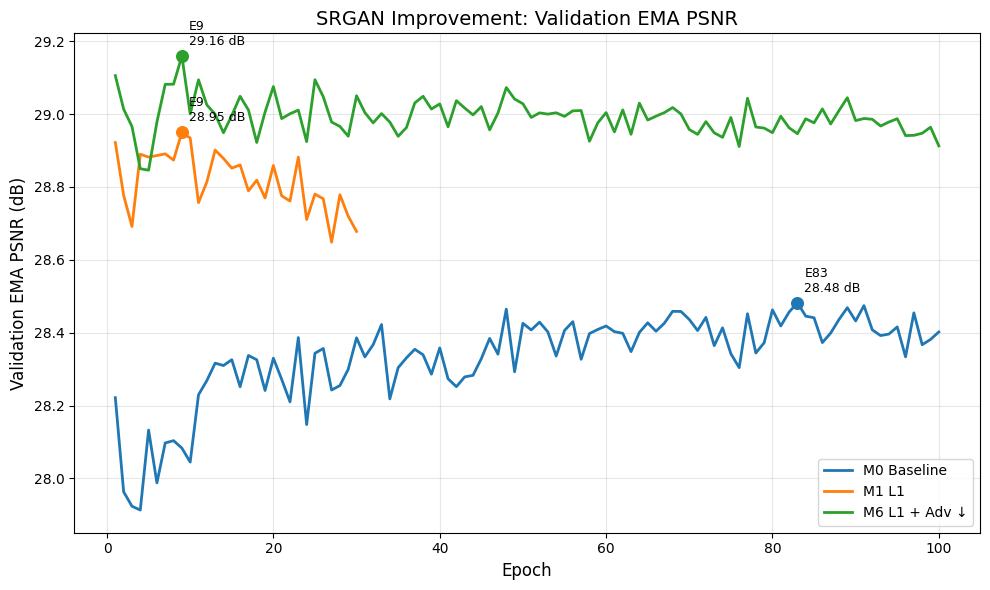

In [8]:
# EMA PSNR curve
plt.figure(figsize=(10, 6))

for name, df in dfs.items():

    plt.plot(
        df["epoch"],
        df["ema_psnr"],
        linewidth=2,
        label=name
    )

    # Best EMA PSNR
    best_idx = df["ema_psnr"].idxmax()
    best_row = df.loc[best_idx]

    plt.scatter(
        best_row["epoch"],
        best_row["ema_psnr"],
        s=70
    )

    plt.annotate(
        f"E{int(best_row['epoch'])}\n"
        f"{best_row['ema_psnr']:.2f} dB",
        (
            best_row["epoch"],
            best_row["ema_psnr"]
        ),
        xytext=(5, 8),
        textcoords="offset points",
        fontsize=9
    )


plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Validation EMA PSNR (dB)", fontsize=12)

plt.title(
    "SRGAN Improvement: Validation EMA PSNR",
    fontsize=14
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

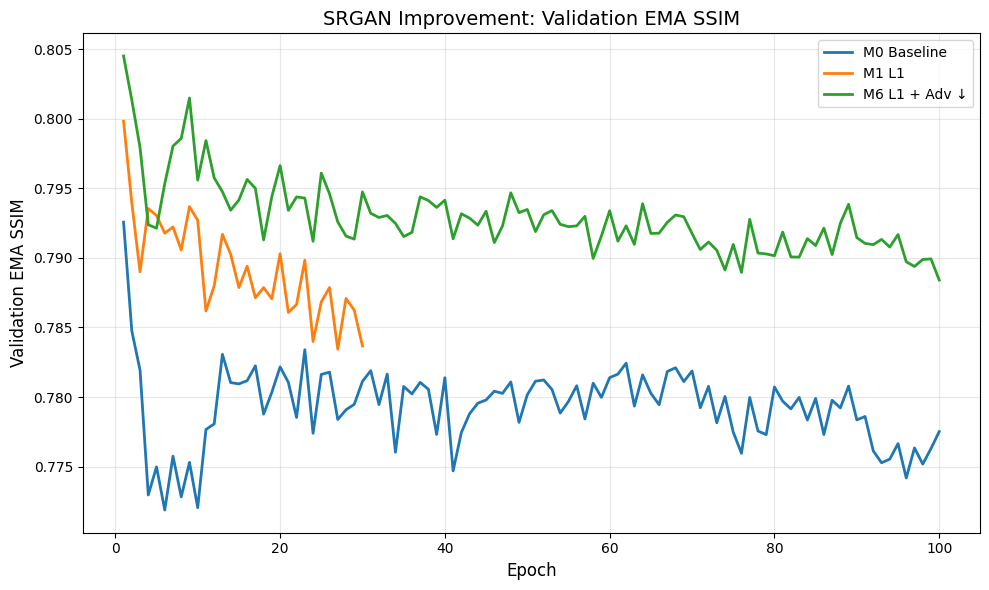

In [7]:
# EMA SSIM curve
plt.figure(figsize=(10, 6))

for name, df in dfs.items():
    plt.plot(df["epoch"], df["ema_ssim"], linewidth=2, label=name)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Validation EMA SSIM", fontsize=12)
plt.title(
    "SRGAN Improvement: Validation EMA SSIM",
    fontsize=14
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [12]:
import numpy as np
import pandas as pd

# M0 vs M6 checkpoint comparison
m0 = dfs["M0 Baseline"]
m6 = dfs["M6 L1 + Adv ↓"]

epochs_to_compare = list(range(10, 101, 10))
rows = []

# Epoch 10, 20, ..., 100
for epoch in epochs_to_compare:
    m0_row = m0[m0["epoch"] == epoch]
    m6_row = m6[m6["epoch"] == epoch]

    if m0_row.empty or m6_row.empty:
        print(
            f"⚠️ Missing epoch {epoch} "
            f"in M0 or M6"
        )
        continue

    m0_row = m0_row.iloc[0]
    m6_row = m6_row.iloc[0]

    rows.append({
        "Checkpoint": f"E{epoch}",

        "M0 PSNR": m0_row["ema_psnr"],
        "M0 SSIM": m0_row["ema_ssim"],

        "M6 PSNR": m6_row["ema_psnr"],
        "M6 SSIM": m6_row["ema_ssim"],

        "ΔPSNR (M6-M0)": (m6_row["ema_psnr"] - m0_row["ema_psnr"]),
        "ΔSSIM (M6-M0)": (m6_row["ema_ssim"] - m0_row["ema_ssim"])
    })

checkpoint_df = pd.DataFrame(rows)

# Independent best checkpoint for each model
m0_best_idx = m0["ema_psnr"].idxmax()
m6_best_idx = m6["ema_psnr"].idxmax()

m0_best = m0.loc[m0_best_idx]
m6_best = m6.loc[m6_best_idx]

best_row = pd.DataFrame([{
    "Checkpoint": (
        f"Best "
        f"(M0:E{int(m0_best['epoch'])}, "
        f"M6:E{int(m6_best['epoch'])})"
    ),

    "M0 PSNR": m0_best["ema_psnr"],
    "M0 SSIM": m0_best["ema_ssim"],

    "M6 PSNR": m6_best["ema_psnr"],
    "M6 SSIM": m6_best["ema_ssim"],

    "ΔPSNR (M6-M0)": (m6_best["ema_psnr"] - m0_best["ema_psnr"]),
    "ΔSSIM (M6-M0)": (m6_best["ema_ssim"] - m0_best["ema_ssim"])
}])

checkpoint_df = pd.concat([checkpoint_df, best_row],ignore_index=True)

display(
    checkpoint_df.style.format({
        "M0 PSNR": "{:.2f}",
        "M0 SSIM": "{:.4f}",

        "M6 PSNR": "{:.2f}",
        "M6 SSIM": "{:.4f}",

        "ΔPSNR (M6-M0)": "{:+.2f}",
        "ΔSSIM (M6-M0)": "{:+.4f}",
    })
)

,Checkpoint,M0 PSNR,M0 SSIM,M6 PSNR,M6 SSIM,ΔPSNR (M6-M0),ΔSSIM (M6-M0)
0,E10,28.04,0.7720,29.00,0.7956,+0.96,+0.0235
1,E20,28.33,0.7822,29.08,0.7966,+0.75,+0.0145
2,E30,28.39,0.7811,29.05,0.7948,+0.66,+0.0136
3,E40,28.36,0.7814,29.03,0.7942,+0.67,+0.0128
4,E50,28.43,0.7802,29.03,0.7935,+0.60,+0.0133
5,E60,28.42,0.7814,29.00,0.7934,+0.59,+0.0120
6,E70,28.44,0.7819,28.96,0.7918,+0.52,+0.0099
7,E80,28.46,0.7807,28.95,0.7902,+0.49,+0.0094
8,E90,28.43,0.7784,28.98,0.7915,+0.55,+0.0131
9,E100,28.40,0.7775,28.91,0.7884,+0.51,+0.0109


In [13]:
print("\n" + "=" * 70)
print("FINAL VALIDATION SUMMARY")
print("=" * 70)

print(
    f"M0 Best EMA: "
    f"Epoch {int(m0_best['epoch'])}, "
    f"PSNR={m0_best['ema_psnr']:.2f}, "
    f"SSIM={m0_best['ema_ssim']:.4f}"
)

print(
    f"M6 Best EMA: "
    f"Epoch {int(m6_best['epoch'])}, "
    f"PSNR={m6_best['ema_psnr']:.2f}, "
    f"SSIM={m6_best['ema_ssim']:.4f}"
)

print(
    f"\nImprovement:"
    f"\nΔPSNR = "
    f"{m6_best['ema_psnr'] - m0_best['ema_psnr']:+.2f} dB"
    f"\nΔSSIM = "
    f"{m6_best['ema_ssim'] - m0_best['ema_ssim']:+.4f}"
)


FINAL VALIDATION SUMMARY
M0 Best EMA: Epoch 83, PSNR=28.48, SSIM=0.7800
M6 Best EMA: Epoch 9, PSNR=29.16, SSIM=0.8015

Improvement:
ΔPSNR = +0.68 dB
ΔSSIM = +0.0215


### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


### Results / Testing

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [27]:
%%writefile test_srresnet_exp_scale.py

import os
import sys
sys.path.append('/content/SRGAN-PyTorch')

import argparse
import torch
from torch.utils.data import DataLoader
from sr_dataset_exp_scale import SRDatasetConfig, SRDataset
from model_srgan import SRResNet
from image_quality_assessment import PSNR, SSIM
from utils import AverageMeter

def get_hr_folder(base_hr, scale):
    """
    如果 base_hr/HR_cropped/X{scale} 存在，则使用裁剪后的 HR，
    否则回退到原始 base_hr。
    """
    hr_cropped_dir = os.path.join(base_hr, 'HR_cropped', f'X{scale}')
    if os.path.isdir(hr_cropped_dir):
        return hr_cropped_dir
    return base_hr

def test_on_benchmark(model_path, benchmark_name, config_params, scale=4):
    """
    测试单个基准数据集
    Args:
        scale (int): 上采样倍数，2,3,4
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Note on Model. Refer to the archived source for the detailed original comment.
    model = SRResNet(channels=64, num_rcb=16, upscale=scale).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    # Note on Dataset, Data. Refer to the archived source for the detailed original comment.
    test_config = SRDatasetConfig(
        csv_folder=config_params['csv_folder'],
        HR_data_folder=config_params['image_folder'],
        LR_data_folder=config_params['lr_folder'],
        crop_size=-1,
        scaling_factor=scale,
        patch_num=1,
        cache=False,
        scale=scale,
        color_augment=False,
        noise_augment=False
    )
    test_dataset = SRDataset(benchmark_name, test_config)
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=2)

    # Note on Evaluation. Refer to the archived source for the detailed original comment.
    psnr_model = PSNR(crop_border=scale, only_test_y_channel=True).to(device)
    ssim_model = SSIM(crop_border=scale, only_test_y_channel=True).to(device)

    psnr_meter = AverageMeter('PSNR', ':6.2f')
    ssim_meter = AverageMeter('SSIM', ':6.4f')

    with torch.no_grad():
        for lr_img, hr_img in test_loader:
            lr_img = lr_img.to(device)
            hr_img = hr_img.to(device)
            sr = model(lr_img)

            # Note on Image. Refer to the archived source for the detailed original comment.
            if sr.shape != hr_img.shape:
                min_h = min(sr.shape[2], hr_img.shape[2])
                min_w = min(sr.shape[3], hr_img.shape[3])
                sr = sr[:, :, :min_h, :min_w]
                hr_img = hr_img[:, :, :min_h, :min_w]

            psnr = psnr_model(sr, hr_img)
            ssim = ssim_model(sr, hr_img)
            psnr_meter.update(psnr.item())
            ssim_meter.update(ssim.item())

    print(f"{benchmark_name}: PSNR = {psnr_meter.avg:.2f} dB, SSIM = {ssim_meter.avg:.4f}")
    return psnr_meter.avg, ssim_meter.avg


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Test SRResNet on benchmarks")
    parser.add_argument('--model_path', type=str,
                        default="/content/drive/MyDrive/DIV2K_Results/srresnet_x4_best_raw.pth",
                        help="Path to the model checkpoint (.pth)")
    parser.add_argument('--scale', type=int, default=4, choices=[2,3,4],
                        help="Upscaling factor of the model")
    parser.add_argument('--csv_folder', type=str,
                        default="/content/drive/MyDrive/DIV2K_Results/output_csv",
                        help="Folder containing CSV files")
    args = parser.parse_args()

    scale = args.scale

    # Note on Dataset, Path, Data. Refer to the archived source for the detailed original comment.
    base_hr_root = "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark"
    base_lr_root = "/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark"

    benchmarks = {
        "Set5": {
            "image_folder": get_hr_folder(f"{base_hr_root}/Set5/HR", scale),
            "lr_folder": f"{base_lr_root}/Set5/LR_bicubic/X{scale}",
            "csv_folder": args.csv_folder
        },
        "Set14": {
            "image_folder": get_hr_folder(f"{base_hr_root}/Set14/HR", scale),
            "lr_folder": f"{base_lr_root}/Set14/LR_bicubic/X{scale}",
            "csv_folder": args.csv_folder
        },
        "Urban100": {
            "image_folder": get_hr_folder(f"{base_hr_root}/Urban100/HR", scale),
            "lr_folder": f"{base_lr_root}/Urban100/LR_bicubic/X{scale}",
            "csv_folder": args.csv_folder
        },
        "BSDS100": {
            "image_folder": get_hr_folder(f"{base_hr_root}/B100/HR", scale),
            "lr_folder": f"{base_lr_root}/B100/LR_bicubic/X{scale}",
            "csv_folder": args.csv_folder
        }
    }

    for name, paths in benchmarks.items():
        test_on_benchmark(
            model_path=args.model_path,
            benchmark_name=name,
            config_params=paths,
            scale=scale
        )

Overwriting test_srresnet_exp_scale.py


In [28]:
#  Note on Testing. Refer to the archived source for the detailed original comment.
model_paths = [
    "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth",
    "/content/drive/MyDrive/DIV2K_Results/output_x4/srgan_baseline_100_best_ema.pth",
    "/content/drive/MyDrive/DIV2K_Results/output_improve_x4/M6_l1_adv5e4_full_x4_best_ema.pth"
]
for path in model_paths:
    print(f"\n===== Testing {path} =====")
    !python test_srresnet_exp_scale.py --model_path {path} --scale 4


===== Testing /content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth =====
Set5: PSNR = 31.88 dB, SSIM = 0.8899
Set14: PSNR = 28.49 dB, SSIM = 0.7782
Urban100: PSNR = 25.75 dB, SSIM = 0.7740
BSDS100: PSNR = 27.49 dB, SSIM = 0.7323

===== Testing /content/drive/MyDrive/DIV2K_Results/output_x4/srgan_baseline_100_best_ema.pth =====
Set5: PSNR = 30.06 dB, SSIM = 0.8499
Set14: PSNR = 27.14 dB, SSIM = 0.7311
Urban100: PSNR = 24.57 dB, SSIM = 0.7291
BSDS100: PSNR = 26.08 dB, SSIM = 0.6716

===== Testing /content/drive/MyDrive/DIV2K_Results/output_improve_x4/M6_l1_adv5e4_full_x4_best_ema.pth =====
Set5: PSNR = 30.44 dB, SSIM = 0.8613
Set14: PSNR = 27.51 dB, SSIM = 0.7455
Urban100: PSNR = 24.63 dB, SSIM = 0.7304
BSDS100: PSNR = 26.68 dB, SSIM = 0.6974


- M6 is better than M0: consistent improvement over the original SRGAN across all four benchmarks
- M6 vs SRResNet: perception–distortion trade-off

### Model

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.

- SRResNet best EMA
- M0 original SRGAN best EMA
- M6 improved SRGAN best EMA


In [33]:
import os
import sys
sys.path.append('/content/SRGAN-PyTorch')

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader

from sr_dataset_exp_scale import SRDatasetConfig, SRDataset
from model_srgan import SRResNet

splits_info_multi = {
    'train': {
        'hr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_HR',
        'lr_folders': {
            '2': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X2',
            '3': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X3',
            '4': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_train_LR_bicubic/X4'
        }
    },
    'valid': {
        'hr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_HR',
        'lr_folders': {
            '2': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X2',
            '3': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X3',
            '4': '/content/drive/MyDrive/datasets/DIV2K_HRLR/DIV2K_valid_LR_bicubic/X4'
        }
    },
    'Set5': {
        'hr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR',
        'lr_folders': {
            '2': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X2',
            '3': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X3',
            '4': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4'
        }
    },
    'Set14': {
        'hr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/HR',
        'lr_folders': {
            '2': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X2',
            '3': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X3',
            '4': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set14/LR_bicubic/X4'
        }
    },
    'Urban100': {
        'hr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/HR',
        'lr_folders': {
            '2': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X2',
            '3': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X3',
            '4': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Urban100/LR_bicubic/X4'
        }
    },
    'BSDS100': {
        'hr_folder': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/HR',
        'lr_folders': {
            '2': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X2',
            '3': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X3',
            '4': '/content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/B100/LR_bicubic/X4'
        }
    },
}


# Helper
def get_hr_folder(split_info, scale):
    """
    Select scale-specific cropped HR folder if it exists.
    Otherwise use the original HR folder.
    """
    hr_base = split_info['hr_folder']
    hr_cropped_dir = os.path.join(hr_base, 'HR_cropped', f'X{scale}')

    if os.path.isdir(hr_cropped_dir):
        return hr_cropped_dir

    return hr_base

def tensor_to_numpy(t):
    """Tensor [1,C,H,W] or [C,H,W] -> numpy [H,W,C]"""
    if t.dim() == 4:
        t = t.squeeze(0)
    t = (t.detach().cpu().clamp(0, 1).numpy())

    return np.transpose(t, (1, 2, 0))


def load_sr_model(path, scale, device):
    model = SRResNet(channels=64, upscale=scale).to(device)
    state_dict = torch.load(path, map_location=device)
    model.load_state_dict(state_dict, strict=True)

    model.eval()

    return model

# Final visual comparison
def visualize_final_comparison(scale=4, benchmark="Set5"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Final checkpoint paths
    srresnet_path = (
        f"/content/drive/MyDrive/DIV2K_Results/"
        f"lr5e5_wd1e5_x{scale}_best_ema.pth"
    )
    m0_path = (
        f"/content/drive/MyDrive/DIV2K_Results/"
        f"output_x{scale}/srgan_baseline_100_best_ema.pth"
    )

    m6_path = (
        f"/content/drive/MyDrive/DIV2K_Results/"
        f"output_improve_x{scale}/M6_l1_adv5e4_full_x{scale}_best_ema.pth"
    )

    # Check files
    model_paths = {
        "SRResNet": srresnet_path,
        "M0 SRGAN": m0_path,
        "M6 Improved SRGAN": m6_path
    }

    for name, path in model_paths.items():
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"{name} checkpoint not found:\n{path}"
            )

    # Dataset
    split_info = splits_info_multi[benchmark]

    hr_folder = get_hr_folder(split_info, scale)
    lr_folder = split_info["lr_folders"][str(scale)]

    print("=" * 70)
    print(f"Benchmark : {benchmark}")
    print(f"Scale     : x{scale}")
    print(f"HR folder : {hr_folder}")
    print(f"LR folder : {lr_folder}")
    print("=" * 70)

    config = SRDatasetConfig(
        csv_folder=("/content/drive/MyDrive/DIV2K_Results/output_csv"),
        HR_data_folder=hr_folder,
        LR_data_folder=lr_folder,
        crop_size=-1,
        scaling_factor=scale,
        patch_num=1,
        cache=False,
        scale=scale,
        color_augment=False,
        noise_augment=False
    )

    dataset = SRDataset(benchmark, config)

    # Models
    srresnet = load_sr_model(srresnet_path, scale, device)
    m0 = load_sr_model(m0_path, scale, device)
    m6 = load_sr_model(m6_path, scale, device)

    # Visualize
    # Set5 show all
    num_display = len(dataset)

    fig, axes = plt.subplots(num_display, 6, figsize=(24, 4 * num_display))

    # Handle case of dataset with one image
    if num_display == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_display):
        lr, hr = dataset[i]
        lr = (lr.unsqueeze(0).to(device))
        hr = (hr.unsqueeze(0).to(device))

        # LR enlarged only for display
        lr_display = F.interpolate(lr, size=hr.shape[-2:],mode="nearest")

        # Bicubic baseline
        bicubic = F.interpolate(
            lr, size=hr.shape[-2:],
            mode="bicubic", align_corners=False
        )

        with torch.no_grad():
            sr_srresnet = srresnet(lr)
            sr_m0 = m0(lr)
            sr_m6 = m6(lr)

        # Strict alignment check
        for name, img in {
            "SRResNet": sr_srresnet,
            "M0": sr_m0,
            "M6": sr_m6
        }.items():

            if img.shape != hr.shape:
                raise ValueError(
                    f"{name}/HR mismatch: "
                    f"{tuple(img.shape)} vs "
                    f"{tuple(hr.shape)}"
                )

        images = [lr_display, bicubic, sr_srresnet, sr_m0, sr_m6, hr]

        titles = [
            "LR Input",
            "Bicubic",
            "SRResNet",
            "M0 SRGAN",
            "M6 Improved SRGAN",
            "HR Ground Truth"
        ]

        for j, (img, title) in enumerate(zip(images, titles)):
            axes[i, j].imshow(tensor_to_numpy(img))

            if i == 0:
                axes[i, j].set_title(title, fontsize=12)

            axes[i, j].axis("off")

    fig.suptitle(
        f"×{scale} Super-Resolution Final Comparison — {benchmark}",
        fontsize=18,
        y=1.01
    )

    plt.tight_layout()
    plt.show()

In [34]:
visualize_final_comparison(scale=4, benchmark="Set5")

Benchmark : Set5
Scale     : x4
HR folder : /content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/HR
LR folder : /content/drive/MyDrive/datasets/DIV2K_HRLR/benchmark/Set5/LR_bicubic/X4


<Figure size 2400x2000 with 30 Axes>

### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [45]:
def visualize_roi_compare(image_name=None, image_idx=0, roi=(120,80,260,220), scale=4, benchmark="Set5"):
    """
    如果指定 image_name，则忽略 image_idx；
    否则使用 image_idx（向后兼容）。
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    srresnet_path = "/content/drive/MyDrive/DIV2K_Results/lr5e5_wd1e5_x4_best_ema.pth"
    m0_path = "/content/drive/MyDrive/DIV2K_Results/output_x4/srgan_baseline_100_best_ema.pth"
    m6_path = f"/content/drive/MyDrive/DIV2K_Results/output_improve_x4/M6_l1_adv5e4_full_x{scale}_best_ema.pth"
    for p in [srresnet_path, m0_path, m6_path]:
        if not os.path.exists(p): raise FileNotFoundError(p)

    split_info = splits_info_multi[benchmark]
    hr_folder = split_info['hr_folder']                     # 直接取，无需额外函数
    lr_folder = split_info["lr_folders"][str(scale)]
    config = SRDatasetConfig(csv_folder="/content/drive/MyDrive/DIV2K_Results/output_csv",
                             HR_data_folder=hr_folder, LR_data_folder=lr_folder,
                             crop_size=-1, scaling_factor=scale, patch_num=1, cache=False,
                             scale=scale, color_augment=False, noise_augment=False)
    dataset = SRDataset(benchmark, config)

    # 如果指定了 image_name，查找索引
    if image_name is not None:
        try:
            image_idx = dataset.HR_images.index(image_name)
        except ValueError:
            raise ValueError(f"Image '{image_name}' not found in {benchmark} dataset.")
    # Note on Use. Refer to the archived source for the detailed original comment.
    if image_idx >= len(dataset): raise ValueError(f"image_idx={image_idx}, only {len(dataset)} images.")

    lr, hr = dataset[image_idx]
    lr, hr = lr.unsqueeze(0).to(device), hr.unsqueeze(0).to(device)

    srresnet = load_sr_model(srresnet_path, scale, device)
    m0 = load_sr_model(m0_path, scale, device)
    m6 = load_sr_model(m6_path, scale, device)

    with torch.no_grad():
        sr_srresnet, sr_m0, sr_m6 = srresnet(lr), m0(lr), m6(lr)
    for name, img in {"SRResNet":sr_srresnet, "M0":sr_m0, "M6":sr_m6}.items():
        if img.shape != hr.shape: raise ValueError(f"{name}/HR shape mismatch: {tuple(img.shape)} vs {tuple(hr.shape)}")

    x1,y1,x2,y2 = roi
    _,_,h,w = hr.shape
    if not (0 <= x1 < x2 <= w and 0 <= y1 < y2 <= h): raise ValueError(f"ROI {roi} outside image size (W={w}, H={h})")

    srresnet_crop = crop_tensor(sr_srresnet, x1,y1,x2,y2)
    m0_crop = crop_tensor(sr_m0, x1,y1,x2,y2)
    m6_crop = crop_tensor(sr_m6, x1,y1,x2,y2)
    hr_crop = crop_tensor(hr, x1,y1,x2,y2)

    images = [srresnet_crop, m0_crop, m6_crop, hr_crop]
    titles = ["SRResNet", "M0 SRGAN", "M6 Improved SRGAN", "HR"]
    fig, axes = plt.subplots(1,4,figsize=(16,4))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(tensor_to_numpy(img))
        ax.set_title(title, fontsize=12)
        ax.axis("off")
    fig.suptitle(f"{benchmark} Image {image_idx} — ROI {roi}", fontsize=14)
    plt.tight_layout()
    plt.show()

### Experiment Notes

This cell documents the image super-resolution experiment. For the full original methodology, mathematical derivations, and commentary, see the archived notebook in `archive/original_notebooks/`.


In [47]:
# 眼睛细节
visualize_roi_compare(
    image_name="baby.png",
    roi=(120, 80, 260, 220),
    scale=4,
    benchmark="Set5"
)

<Figure size 1600x400 with 4 Axes>

In [49]:
# 嘴 手细节
visualize_roi_compare(
    image_name="woman.png",
    roi=(100, 160, 200, 290),
    scale=4,
    benchmark="Set5"
)

<Figure size 1600x400 with 4 Axes>

In [48]:
# 花球细节
visualize_roi_compare(
    image_name='19021.png',
    roi=(210, 30, 420, 210),
    scale=4,
    benchmark="BSDS100"
)

<Figure size 1600x400 with 4 Axes>